# Лабораторна робота № 6
## Конвеєр інтелектуального аналізу даних та інтерпретація моделі

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик інтернет-провайдера. Маркетинг просить модель, яка **в момент
звернення клієнта** оцінює ризик, що той розірве договір протягом кварталу.
Модель потрібна не заради числа: за її підказкою відділ утримання
телефонуватиме людям і пропонуватиме знижку. Тому від вас хочуть **дві речі**:

1. чесну оцінку якості;
2. **пояснення**, чому модель вважає конкретного клієнта ризиковим.

Вам видали вивантаження з CRM. Воно зроблене не для аналізу, а для звітності,
тому в ньому є все підряд — зокрема й те, чого в момент прогнозу ще не існує.

> **Попередження, яке варто прочитати двічі.** Перший результат, який ви
> отримаєте, буде прекрасним. Робота полягає в тому, щоб з'ясувати, чому
> йому не можна вірити, і скільки залишиться після того, як ви приберете
> все зайве.

### Що здаєте

Цей ноутбук із заповненими комірками, виконаними **згори вниз без помилок**,
і відповідями на питання розділу 16.

### Як оцінюється

| Частина | Що оцінюється | Балів |
|---|---|---|
| 1 | Конвеєр: обробка, витік, чесне число, вибір методу | 2,0 |
| 2 | Інтерпретація: важливість, PDP, SHAP | 1,5 |
| 3 | Звіт: обґрунтування рішень і виявлені хибні інтерпретації | 0,5 |

Штраф −0,5 бала, якщо ноутбук не виконується згори вниз на чистому ядрі.

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Файл даних підтягнеться сам.

In [1]:
STUDENT_NAME = 'Лящук Соломія'
LIST_NUMBER  = 6      # номер у списку групи

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
VARIANT = (LIST_NUMBER - 1) % 30 + 1
DATA = 'lr6_варіант_%02d.csv' % VARIANT
print('варіант %d, файл %s' % (VARIANT, DATA))

варіант 6, файл lr6_варіант_06.csv


>  **Коротко.** Номер у списку 6 → варіант 6 → файл `lr6_варіант_06.csv`. Формула `(номер − 1) mod 30 + 1` просто «загортає» номер у діапазон 1–30.

In [2]:
import importlib.util, subprocess, sys
REQUIRED = ['pandas', 'numpy', 'scikit-learn', 'matplotlib', 'shap']
MODNAME  = {'scikit-learn': 'sklearn'}
missing = [p for p in REQUIRED if importlib.util.find_spec(MODNAME.get(p, p)) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [3]:
import warnings; warnings.filterwarnings('ignore')
import os, re, json, time, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import (RepeatedStratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

SEED = 42
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
print('усе імпортовано')

усе імпортовано


---
## 1. Три рішення, які ухвалюють ДО того, як торкнутись даних

Нагадування з лекції 7: кроки 1–3 алгоритму виконуються перш ніж
ви напишете хоч один рядок обробки. Якщо обрати метрику після того, як
побачив результати, ви оберете ту, яка показала більше.

### Завдання 1.1

Заповніть три змінні нижче і **обґрунтуйте кожну** одним реченням у коментарі.

In [ ]:

TYPE_OF_TASK = 'класифікація'

METRIC = 'AUC'

CV_SCHEME = 'стратифікована 5-кратна, 4 повтори'

for nme, val in [('TYPE_OF_TASK', TYPE_OF_TASK), ('METRIC', METRIC), ('CV_SCHEME', CV_SCHEME)]:
    assert val, 'не заповнено: ' + nme
print('рішення зафіксовані')

рішення зафіксовані


> Три рішення *до* роботи з даними:
> - **тип задачі** — класифікація (відповідь «так/ні»);
> - **метрика AUC** — це ймовірність, що випадково взятий клієнт, який пішов, отримає вищий ризик, ніж випадковий клієнт, який лишився (0,5 — вгадування, 1 — ідеал); не залежить від порогу;
> - **схема** — 5 згорток × 4 повтори = 20 навчань, береться середнє і розкид.

---
## 2. Перший погляд на дані

### Завдання 2.1

Прочитайте файл і дайте відповідь на чотири питання: скільки рядків і стовпців,
яка частка відтоку, скільки стовпців має невизначений тип, де найбільше пропусків.

In [5]:
raw = pd.read_csv(os.path.join('дані', DATA), encoding='utf-8-sig')
TARGET = 'відтік'

print('розмір:', raw.shape)
print('частка відтоку: %.3f' % raw[TARGET].mean())
print()
print('типи стовпців:', raw.dtypes.astype(str).value_counts().to_dict())

розмір: (1200, 26)
частка відтоку: 0.286

типи стовпців: {'str': 13, 'float64': 8, 'int64': 5}


In [6]:
tab = pd.DataFrame({
    'тип': raw.dtypes.astype(str),
    'унікальних': raw.nunique(),
    '% пропусків': (raw.isna().mean() * 100).round(1),
    'приклад': [raw[c].dropna().iloc[0] for c in raw.columns],
}).rename_axis('стовпець').sort_values('% пропусків', ascending=False)
display(tab)

n_text = int((raw.dtypes.astype(str).isin(['object', 'str', 'string'])).sum())
print('рядків: %d, стовпців: %d' % raw.shape)
print('частка відтоку: %.3f' % raw[TARGET].mean())
print('стовпців із текстовим типом: %d' % n_text)
print('найбільше пропусків: %s (%.1f %%)' % (tab.index[0], tab['% пропусків'].iloc[0]))

,тип,унікальних,% пропусків,приклад
стовпець,,,,
сума_повернення_депозиту,float64,341,71.4,100.25
дата_розірвання,str,286,71.4,2025-04-07
середній_час_відповіді_хв,float64,263,33.3,13.2
трафік_ГБ,str,982,5.0,146.0
щомісячний_платіж,str,1128,4.0,306.12
аварій_на_ділянці_за_квартал,float64,5,3.0,1.0
стать,str,6,0.0,Ж
місто,str,6,0.0,Львів
id_клієнта,str,1200,0.0,K60000


рядків: 1200, стовпців: 26
частка відтоку: 0.286
стовпців із текстовим типом: 13
найбільше пропусків: сума_повернення_депозиту (71.4 %)


> Таблиця показує для кожного стовпця тип, кількість різних значень, % пропусків і приклад. Після неї відповіді на 4 питання:
> - **1200 рядків × 26 стовпців**;
> - відтік **28,6 %** (отже «ніхто не піде» дає ~71,4 % точності);
> - **текстових стовпців 13**, а серед них — два, які мали бути числами (`щомісячний_платіж`, `трафік_ГБ`), їхній тип «невизначений»;
> - найбільше пропусків — у `дата_розірвання` і `сума_повернення_депозиту`: **71,4 %** (це рівно ті, хто лишився).

### Завдання 2.2 — три способи, якими дані вже зіпсовані

У вивантаженні є щонайменше три проблеми, кожна з яких тихо зламає модель.
Знайдіть їх і **назвіть конкретні стовпці**.

1. Числова колонка, у якій частина значень записана **текстом**.
2. Колонка, у якій Excel перетворив число на **дату**.
3. Колонка, пропуски в якій **не випадкові** — їхня наявність сама щось означає
   (механізм MNAR за класифікацією Рубіна, розділ 7.2 конспекту).

In [ ]:
txt = raw['щомісячний_платіж'].dropna()
print('щомісячний_платіж — із текстом "грн":', int(txt.astype(str).str.contains('грн').sum()), 'з', len(txt))
print(txt[txt.astype(str).str.contains('грн')].head(4).tolist())

gb = raw['трафік_ГБ'].dropna().astype(str)
bad = gb[gb.str.startswith('1900-')]
print('\nтрафік_ГБ — значень-«дат»:', len(bad), '; приклади:', bad.head(3).tolist())

print('\nсередній_час_відповіді_хв: пропусків', int(raw['середній_час_відповіді_хв'].isna().sum()))
print(pd.crosstab(raw['кількість_звернень_у_підтримку'], raw['середній_час_відповіді_хв'].isna(),
                  rownames=['звернень'], colnames=['пропуск часу відповіді']))

щомісячний_платіж — із текстом "грн": 25 з 1152
['277.16 грн', '298.44 грн', '676.6 грн', '305.51 грн']

трафік_ГБ — значень-«дат»: 3 ; приклади: ['1900-01-24 00:00:00', '1900-01-10 00:00:00', '1900-01-09 00:00:00']

середній_час_відповіді_хв: пропусків 400
пропуск часу відповіді  False  True 
звернень                            
0                           0    400
1                         420      0
2                         272      0
3                          78      0
4                          21      0
5                           7      0
6                           2      0


In [ ]:
PROBLEM_TEXT_IN_NUMBER = 'щомісячний_платіж'   
PROBLEM_EXCEL_DATE     = 'трафік_ГБ'           
PROBLEM_MNAR           = 'середній_час_відповіді_хв'
MNAR_MEANING           = ('пропуск = клієнт жодного разу не звертався у підтримку '
                          '(звернень 0), тому часу відповіді просто не існує')

for nme, val in [('PROBLEM_TEXT_IN_NUMBER', PROBLEM_TEXT_IN_NUMBER),
                 ('PROBLEM_EXCEL_DATE', PROBLEM_EXCEL_DATE),
                 ('PROBLEM_MNAR', PROBLEM_MNAR), ('MNAR_MEANING', MNAR_MEANING)]:
    assert val, 'не заповнено: ' + nme
assert PROBLEM_TEXT_IN_NUMBER in raw.columns and PROBLEM_EXCEL_DATE in raw.columns
assert PROBLEM_MNAR in raw.columns
print('проблеми названо')

проблеми названо


>  Три «зіпсовані» стовпці:
> 1. **`щомісячний_платіж`** — частина значень із текстом «грн» (`'277.16 грн'`): модель такого не з'їсть, треба витягти число.
> 2. **`трафік_ГБ`** — Excel побачив, наприклад, `24` і зробив із цього дату `1900-01-24` (день №24 від 1900 року). Це **брак, а не дані**, тому правильна відповідь — `NaN`, а не число з дати.
> 3. **`середній_час_відповіді_хв`** — пропуски **не випадкові (MNAR)**: вони є рівно у клієнтів із 0 звернень. Немає звернення → нема що міряти. Сам факт пропуску несе інформацію.

---
## 3. Будуємо матрицю ознак

Перетворення сирої таблиці на матрицю `X` — це фаза 3 CRISP-DM. Усі рішення
тут приймаються **явно** і записуються, бо потім їх доведеться захищати.

### Завдання 3.1

Допишіть `to_number` і `build_X`.

* `to_number` має витягати число з тексту `'350.5 грн'`, **не** перетворювати
  дату на число і повертати `NaN` там, де числа немає.
* `build_X` для кожного стовпця вирішує: число, категорія чи викинути.
  Дата підключення має стати **числом** (напр. порядковим номером дня) —
  інакше модель її не з'їсть.

In [ ]:
_DATE = re.compile(r'^\d{4}-\d{2}-\d{2}')    
_NUM = re.compile(r'-?\d+(?:\.\d+)?')           

def to_number(s):
    """Витягує число з колонки, де перемішані числа, текст і дати."""
    def one(v):
        if v is None or (isinstance(v, float) and np.isnan(v)):    
            return np.nan
        if isinstance(v, (datetime.datetime, pd.Timestamp)):          
            return np.nan
        if isinstance(v, (int, float, np.integer, np.floating)):     
            return float(v)
        t = str(v).strip()
        if _DATE.match(t):            
            return np.nan
        m = _NUM.search(t.replace(',', '.'))   
        return float(m.group()) if m else np.nan                   
    return s.map(one)


_t = pd.Series([1, '350.5 грн', '2,75', datetime.datetime(1900, 1, 11), None, 'немає'])
_r = to_number(_t)
assert _r[0] == 1.0 and abs(_r[1] - 350.5) < 1e-9 and abs(_r[2] - 2.75) < 1e-9
assert np.isnan(_r[3]), 'дата має стати NaN, а не числом'
assert np.isnan(_r[4]) and np.isnan(_r[5])
print('to_number працює')

to_number працює


>  `to_number` для кожного значення питає по черзі: порожньо → `NaN`; дата → `NaN` (головна пастка: `1900-01-11` не можна читати як «1900» чи «11»); число → як є; текст → перше число в ньому (кома стає крапкою: `'2,75'` → 2.75), якщо числа немає (`'немає'`) → `NaN`.

In [ ]:
DROP_ALWAYS = ['id_клієнта']  

_NUMTXT = re.compile(r'\s*-?\d+(?:[.,]\d+)?\s*(?:грн|гб|мб|мбіт)?\s*|\d{4}-\d{2}-\d{2}.*', re.I)

def build_X(d, drop):
    """Сира таблиця -> матриця ознак. Категорії лишаємо типом category."""
    X = pd.DataFrame(index=d.index)
    log = []
    for c in d.columns:
        if c in drop or c == TARGET:
            continue
        s = d[c]
        if c.startswith('дата_'):
            dt = pd.to_datetime(s, errors='coerce')
            X[c] = (dt - pd.Timestamp('2023-01-01')).dt.days.astype(float)
            how = 'дата -> номер дня'
        elif s.dtype == object or str(s.dtype).startswith('str'):
            if s.dropna().astype(str).str.fullmatch(_NUMTXT).mean() > 0.8:
                X[c] = to_number(s)
                how = 'текст -> число'
            else:
                t = s.str.strip().str.lower()          # регістр і пробіли
                if c == 'стать':                       # ч / чол / Ч — те саме
                    t = t.replace({'чол': 'ч', 'жін': 'ж'})
                X[c] = t.astype('category')
                how = 'категорія'
        else:
            X[c] = s.astype(float)
            how = 'число'
        log.append({'стовпець': c, 'що зроблено': how})
    return X, pd.DataFrame(log)


X_all, log = build_X(raw, DROP_ALWAYS)
y = raw[TARGET].astype(int)
print('матриця ознак:', X_all.shape)
print('категоріальних:', sum(str(X_all[c].dtype) == 'category' for c in X_all.columns))
display(log)

матриця ознак: (1200, 24)
категоріальних: 8


,стовпець,що зроблено
0,вік,число
1,стать,категорія
2,місто,категорія
3,філія,категорія
4,тариф,категорія
5,тип_підключення,категорія
6,спосіб_оплати,категорія
7,автоплатіж,категорія
8,кількість_послуг,число
9,місяців_обслуговування,число


>  `build_X` проходить по стовпцях і вирішує, чим кожен стане:
> - `дата_…` → число (дні від 01.01.2023);
> - текст, де >80 % значень — «число з приміткою» (`'277.16 грн'`) → число через `to_number`;
> - інший текст → категорія (до нижнього регістру, без зайвих пробілів; у `стать` «ч», «чол», «Ч» зливаються в одне, тому 6 варіантів стали 2);
> - число → `float`.
>
> `id_клієнта` викидаємо одразу: він унікальний для кожного, модель лише «запам'ятала б» людей.

### Завдання 3.2 — конвеєр

Зберіть `make_pipe(X, clf)`: колонковий перетворювач (числові — медіана плюс
стандартизація; категоріальні — мода плюс одиничне кодування) і модель.

> **Чому саме так.** Відповідь у розділі 10 конспекту: усе, що має `fit`,
> мусить опинитись **усередині** конвеєра, інакше крос-валідація бреше.
> Зверніть увагу на `handle_unknown='ignore'` — без нього модель упаде на
> категорії, якої не було в навчальній згортці.

In [ ]:
def make_pipe(X, clf):
    cat = [c for c in X.columns if str(X[c].dtype) == 'category']
    num = [c for c in X.columns if c not in cat]
    prep = ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median', add_indicator=True)),
                          ('sc', StandardScaler())]), num),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                          ('oh', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat),
    ], sparse_threshold=0)
    return Pipeline([('prep', prep), ('clf', clf)])


def logreg():
    return LogisticRegression(max_iter=3000, random_state=SEED)


cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=SEED)

_p = make_pipe(X_all, logreg())
assert hasattr(_p, 'fit') and hasattr(_p, 'predict')
_s = cross_val_score(_p, X_all, y, cv=RepeatedStratifiedKFold(
    n_splits=5, n_repeats=1, random_state=SEED), scoring='roc_auc')
assert len(_s) == 5
print('конвеєр зібрано, пробний прогін AUC %.3f' % _s.mean())

конвеєр зібрано, пробний прогін AUC 1.000


> `make_pipe` — це «конвеєр»: обробка + модель в одному об'єкті. Усе, що щось «вчить» із даних (медіана, середнє для стандартизації, список категорій), відбувається **всередині** кожної згортки крос-валідації, тільки на її навчальній частині. Так перевірочна частина нічого не «підглядає» (немає препроцесингового витоку).
> - `add_indicator=True` додає колонку «значення було пропущене» — щоб факт пропуску не губився після заповнення медіаною;
> - `handle_unknown='ignore'` — щоб модель не впала на категорії, якої не було в навчанні (у `код_тарифного_плану` їх 40);
> - `sparse_output=False` — щоб кодування було звичайною таблицею (для SHAP далі).

---
## 4. Перший результат

Запустіть модель на **всьому, що є**, — саме так робить дев'ять аналітиків
із десяти, коли їм дали вивантаження і попросили «подивитись, чи взагалі
щось передбачається».

In [12]:
t0 = time.time()
auc_naive = cross_val_score(make_pipe(X_all, logreg()), X_all, y, cv=cv, scoring='roc_auc')
print('ознак    : %d' % X_all.shape[1])
print('AUC      : %.3f ± %.3f' % (auc_naive.mean(), auc_naive.std()))
print('час      : %.1f c' % (time.time() - t0))

ознак    : 24
AUC      : 1.000 ± 0.000
час      : 0.5 c


>  Перший результат на *всьому, що є*, виглядає ідеально — і саме тому йому не можна вірити. Точне число дивись у виводі вище.

### Завдання 4.1

Подивіться на число і на таблицю орієнтирів AUC з розділу 4.4 конспекту.

Запишіть у `FIRST_REACTION` одне речення: що саме це число означає
і яка з двох причин високої AUC, найімовірніше, спрацювала.

In [13]:
FIRST_REACTION = ('AUC ≈ 1.0 — «ідеальна» модель, що для реальних даних нереально; з двох причин '
                  '(справжній сигнал чи витік) спрацював ВИТІК: у даних є стовпці, яких не існує '
                  'в момент прогнозу (дата розірвання, повернення депозиту), їх заповнено тільки в тих, хто пішов.')
assert FIRST_REACTION, 'напишіть, що ви думаєте про це число'
print(FIRST_REACTION)

AUC ≈ 1.0 — «ідеальна» модель, що для реальних даних нереально; з двох причин (справжній сигнал чи витік) спрацював ВИТІК: у даних є стовпці, яких не існує в момент прогнозу (дата розірвання, повернення депозиту), їх заповнено тільки в тих, хто пішов.


> Орієнтири: AUC 0,8–0,9 — добра модель, **0,95+ на реальних даних — майже завжди витік**. Ми отримали ≈1,000 з розкидом 0 — це ознака, що ціль «підглянули» через стовпець.

---
## 5. Шукаємо витік

Чотири типи витоку (розділ 9.1 конспекту) і засіб проти кожного:

| Тип | Засіб |
|---|---|
| цільовий | чек-ліст: чи існує значення в момент прогнозу |
| препроцесинговий | конвеєр |
| часовий | часова схема перевірки |
| груповий | групова схема перевірки |

Починаємо з цільового.

### Завдання 5.1 — автоматичний детектор

Напишіть `leak_scan`: для кожного стовпця перевірте, чи **сам факт
заповненості** передбачає клас. Поріг `min_group` обов'язковий — без нього
детектор видає хибні спрацювання на колонках, заповнених у двох клієнтів.

In [ ]:
def leak_scan(d, y, min_group=20):
    rows = []
    for c in d.columns:
        if c == TARGET:
            continue
        filled = d[c].notna().astype(int)
        n1, n0 = int(filled.sum()), int((1 - filled).sum())
        if n1 < min_group or n0 < min_group:      # одна з груп замала -> не рахуємо
            continue
        a = roc_auc_score(y, filled)
        rows.append({'ознака': c, 'заповнено': n1,
                     'частка_відтоку_де_заповнено': y[filled == 1].mean(),
                     'частка_відтоку_де_пропуск': y[filled == 0].mean(),
                     'показник': max(a, 1 - a)})   # напрям не важливий: важливо, що ділить
    return pd.DataFrame(rows).sort_values('показник', ascending=False)


scan = leak_scan(raw, y)
display(scan.head(10))

,ознака,заповнено,частка_відтоку_де_заповнено,частка_відтоку_де_пропуск,показник
4,дата_розірвання,343,1.000000,0.000000,1.000000
5,сума_повернення_депозиту,343,1.000000,0.000000,1.000000
3,середній_час_відповіді_хв,800,0.320000,0.217500,0.555792
1,трафік_ГБ,1140,0.291228,0.183333,0.512553
0,щомісячний_платіж,1152,0.281250,0.395833,0.510777
2,аварій_на_ділянці_за_квартал,1164,0.289519,0.166667,0.508757


> Детектор бере лише *факт* «заповнено / порожньо» кожного стовпця і дивиться, чи він ділить клієнтів на тих, хто пішов, і тих, хто лишився. 1,0 = ідеально ділить = стовпець записаний уже після відтоку. `min_group=20` — не рахуємо стовпці, де одна з груп менша за 20 клієнтів (там випадковість дає красиві, але фальшиві числа).

### Завдання 5.2 — цільовий витік

Стовпці з показником близько 1,0 заповнені **лише в одного класу**. Такий
стовпець записаний уже після того, як результат став відомий.

Випишіть їх у `TARGET_LEAK` і **для кожного поясніть одним реченням**, чому
його не існує в момент прогнозу.

In [ ]:
TARGET_LEAK = [
    'дата_розірвання',         
    'сума_повернення_депозиту', 
]
assert len(TARGET_LEAK) >= 2, 'таких стовпців більше ніж один'
assert all(c in raw.columns for c in TARGET_LEAK)
print('цільовий витік:', TARGET_LEAK)

цільовий витік: ['дата_розірвання', 'сума_повернення_депозиту']


>  Обидва стовпці заповнені **тільки** у тих, хто пішов (по 71,4 % порожніх = ті, хто лишився). Момент прогнозу — клієнт ще на зв'язку, договір чинний: ні дати розірвання, ні повернення депозиту ще немає. Це **цільовий витік** — ознака є наслідком цілі.

In [16]:
X2, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK)
auc2 = cross_val_score(make_pipe(X2, logreg()), X2, y, cv=cv, scoring='roc_auc')
print('після вилучення цільового витоку: %d ознак, AUC %.3f ± %.3f'
      % (X2.shape[1], auc2.mean(), auc2.std()))

після вилучення цільового витоку: 22 ознак, AUC 0.975 ± 0.008


> 💬 **Коротко.** Прибрали два явні стовпці-наслідки — а AUC майже не впав (≈ 1,000 → 0,975). Це не помилка: детектор знаходить лише те, що **формально** пов'язане з ціллю, а головний витік ще лишився (див. 5.3).

### Завдання 5.3 — витік, якого детектор НЕ бачить

Число майже не впало. Отже головне ще попереду.

Детектор знаходить колонки, **формально** пов'язані з ціллю. Він безсилий
проти колонки, яка формально бездоганна, але якої **не існує в момент,
коли ухвалюється рішення** — або яка означає не те, що здається.

Перегляньте решту стовпців **очима** і поставте кожному питання з розділу 9.3:

> **Чи міг я знати це значення в ту мить, коли треба ухвалити рішення?**

Нагадування про момент прогнозу: клієнт щойно зателефонував, договір
**чинний**, рішення про знижку ухвалюється **зараз**.

In [ ]:
print(list(X2.columns))

solo = {}
for c in X2.columns:
    v = X2[c]
    if str(v.dtype) == 'category':
        v = v.cat.codes
    v = v.fillna(v.median())
    a = roc_auc_score(y, v)
    solo[c] = max(a, 1 - a)
display(pd.Series(solo).sort_values(ascending=False).round(3).head(6).to_frame('AUC однієї ознаки'))
print(raw.groupby('оцінка_ризику_менеджером')[TARGET].agg(['mean', 'size']).round(3))

['вік', 'стать', 'місто', 'філія', 'тариф', 'тип_підключення', 'спосіб_оплати', 'автоплатіж', 'кількість_послуг', 'місяців_обслуговування', 'швидкість_тарифу_Мбіт', 'щомісячний_платіж', 'знижка_відсоток', 'трафік_ГБ', 'кількість_звернень_у_підтримку', 'аварій_на_ділянці_за_квартал', 'середній_час_відповіді_хв', 'трафік_МБ', 'код_тарифного_плану', 'скоринг_партнера', 'дата_підключення', 'оцінка_ризику_менеджером']


,AUC однієї ознаки
оцінка_ризику_менеджером,0.946
щомісячний_платіж,0.670
швидкість_тарифу_Мбіт,0.662
місяців_обслуговування,0.644
вік,0.643
трафік_МБ,0.638


                           mean  size
оцінка_ризику_менеджером             
1.0                       0.000   250
2.0                       0.019   372
3.0                       0.267   285
4.0                       0.815   173
5.0                       0.992   120


In [ ]:
HUMAN_LEAK = [
    'оцінка_ризику_менеджером',  
]
HUMAN_LEAK_WHY = ('поле заповнене в усіх 1200 клієнтів, тож «заповненість» не ділить класи '
                  'і детектор його не бачить; витік тут у ЗНАЧЕННІ, а не в пропусках: '
                  'бал 1–2 майже не відтікають, а 5 — майже всі')

assert len(HUMAN_LEAK) >= 1 and HUMAN_LEAK_WHY
assert all(c in raw.columns for c in HUMAN_LEAK)
X3, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK)
auc3 = cross_val_score(make_pipe(X3, logreg()), X3, y, cv=cv, scoring='roc_auc')
print('після вилучення оцінок людини: %d ознак, AUC %.3f ± %.3f'
      % (X3.shape[1], auc3.mean(), auc3.std()))

після вилучення оцінок людини: 21 ознак, AUC 0.830 ± 0.022


>  `оцінка_ризику_менеджером` — оцінку ставить **людина, яка вже бачила, як клієнт себе веде** (і навіть чи він пішов). Бали 1–2 → майже ніхто не пішов, бал 5 → пішли майже всі (цифри у таблиці вище). Детектор це не бачить, бо стовпець заповнений у **всіх** — хитрість не в пропусках, а в значеннях. Після вилучення AUC падає з ~0,97 до ~0,83: це і є головний поворот роботи.

> Якщо тут число впало **суттєво** — ви знайшли головне. Якщо ні —
> перечитайте список стовпців ще раз: щось лишилось.

---
## 6. Артефакт збору даних

Лишилась найтонша перевірка. Якщо дані про два класи **збиралися
по-різному** — у різні періоди, різними людьми, за різними правилами —
модель вивчає спосіб запису, а не предмет. Жодна окрема колонка при цьому
не є витоком; витоком є вся таблиця.

Обчислювана перевірка з розділу 9.3: спробувати передбачити **не ціль,
а джерело**. Якщо за тими самими чесними ознаками добре вгадується філія
або період підключення — класи не порівнянні між собою.

### Завдання 6.1 — частка відтоку за філіями і за періодом

,частка відтоку,клієнтів
філія,,
Ф-01 Центр,0.275,233
Ф-02 Захід,0.296,186
Ф-03 Схід,0.265,170
Ф-04 Південь,0.294,194
Ф-05 Північ,0.328,204
Ф-06 Приміська,0.258,213


,частка відтоку,клієнтів
дата_підключення,,
2023Q1,0.178,146
2023Q2,0.220,127
2023Q3,0.213,155
2023Q4,0.230,178
2024Q1,0.219,146
2024Q2,0.404,166
2024Q3,0.394,132
2024Q4,0.427,150


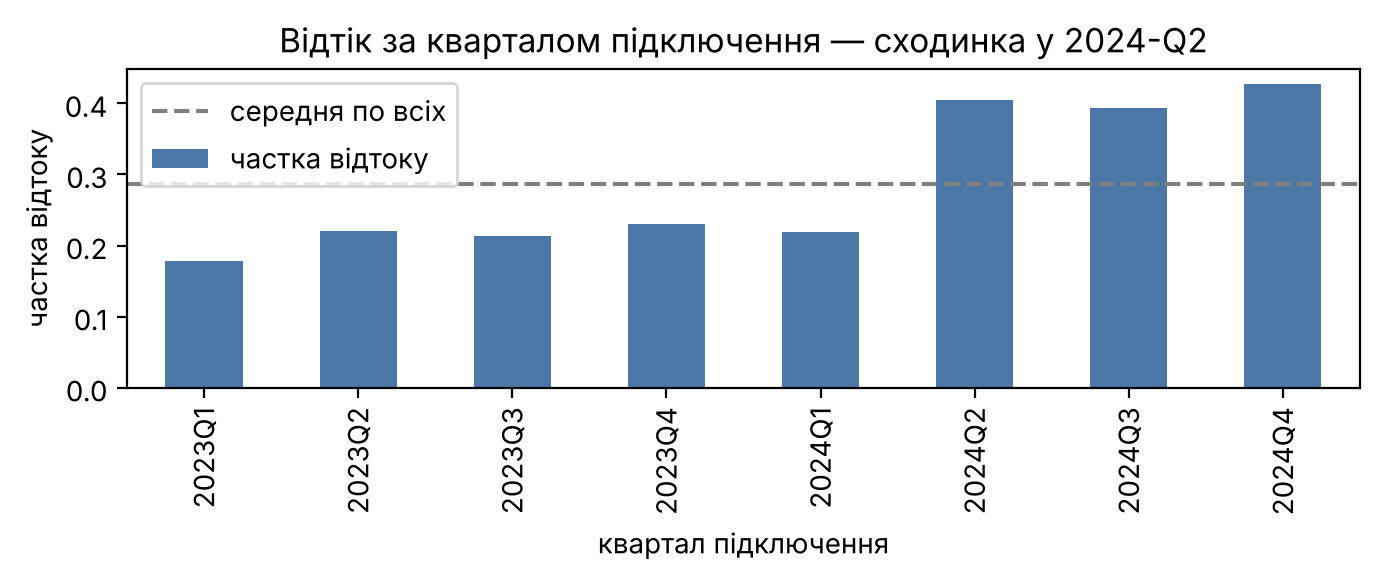

,до 2024-04-01,з 2024-04-01
швидкість_тарифу_Мбіт,,
50,0.11,0.29
100,0.13,0.33
200,0.20,0.37
300,0.25,0.44
400,0.14,0.40
500,0.40,0.62
600,0.29,0.46
800,NaN,0.14
1000,0.74,0.63


In [ ]:
by_branch = raw.groupby('філія')[TARGET].agg(['mean', 'size']).round(3)
by_branch.columns = ['частка відтоку', 'клієнтів']
display(by_branch)

dt_conn = pd.to_datetime(raw['дата_підключення'])
by_q = raw.groupby(dt_conn.dt.to_period('Q'))[TARGET].agg(['mean', 'size']).round(3)
by_q.columns = ['частка відтоку', 'клієнтів']
display(by_q)

ax = by_q['частка відтоку'].plot(kind='bar', figsize=(7, 3), color='#4C78A8')
ax.axhline(raw[TARGET].mean(), ls='--', c='grey', label='середня по всіх')
ax.set_ylabel('частка відтоку'); ax.set_xlabel('квартал підключення'); ax.legend()
plt.title('Відтік за кварталом підключення — сходинка у 2024-Q2')
plt.tight_layout(); plt.show()

chk = raw.assign(після=(dt_conn >= '2024-04-01').astype(int)).pivot_table(
    index='швидкість_тарифу_Мбіт', columns='після', values=TARGET, aggfunc='mean').round(2)
chk.columns = ['до 2024-04-01', 'з 2024-04-01']
display(chk)

>  Шукаємо **сходинку**, а не плавний нахил.
> - За **філіями** частка відтоку майже однакова (26–33 %) — філія не підозріла.
> - За **кварталами підключення**: у 2023–2024-Q1 відтік ~18–23 %, а з **2024-Q2 стрибає до ~40 %** і так лишається. Це різкий злам ~1 квітня 2024.
> - У нижній таблиці видно: злам є **в кожній швидкості тарифу**, тобто це не «прийшли інші клієнти», а ніби змінилися правила обліку (хто вважається таким, що пішов). Тому підозрюю `дата_підключення`.

### Завдання 6.2 — передбачити джерело

Візьміть **ті самі чесні ознаки**, що й для моделі відтоку, і спробуйте
передбачити ними не `відтік`, а ознаку джерела: «клієнт із філії-підозрюваної»
або «підключений після дати-зламу».

Якщо AUC помітно вища за 0,5 — у ваших даних закодоване джерело.

In [ ]:
SUSPECT = 'дата_підключення'     
assert SUSPECT in ('філія', 'дата_підключення')

source = (pd.to_datetime(raw['дата_підключення']) >= '2024-04-01').astype(int)
print('після зламу: %d клієнтів (%.1f %%)' % (source.sum(), 100 * source.mean()))

X4, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK + [SUSPECT])
auc_src = cross_val_score(make_pipe(X4, logreg()), X4, source, cv=cv, scoring='roc_auc')
auc4 = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
print('ті самі ознаки передбачають ДЖЕРЕЛО : AUC %.3f' % auc_src.mean())
print('ті самі ознаки передбачають ВІДТІК  : AUC %.3f ± %.3f' % (auc4.mean(), auc4.std()))

після зламу: 448 клієнтів (37.3 %)


ті самі ознаки передбачають ДЖЕРЕЛО : AUC 0.751
ті самі ознаки передбачають ВІДТІК  : AUC 0.814 ± 0.022


> Ідея перевірки: беремо ті самі «чесні» ознаки і просимо передбачити не відтік, а **«підключений після зламу чи ні»**. Якби дві групи були однакові, AUC ≈ 0,5. Вийшло значно більше → групи **різні за складом** (після зламу клієнти частіше на оптиці, з автоплатежем і швидшими тарифами). Тобто «хвіст» таблиці зібраний не так, як «голова», і модель може вчити цю різницю замість причин відтоку.

### Завдання 6.3 — драбина

Зведіть усі чотири числа в одну таблицю і подивіться, **де саме** впало.

In [21]:
ladder = pd.DataFrame([
    {'крок': '1. усе підряд',               'ознак': X_all.shape[1], 'AUC': auc_naive.mean()},
    {'крок': '2. мінус цільовий витік',     'ознак': X2.shape[1],    'AUC': auc2.mean()},
    {'крок': '3. мінус оцінки людини',      'ознак': X3.shape[1],    'AUC': auc3.mean()},
    {'крок': '4. мінус артефакт збору',     'ознак': X4.shape[1],    'AUC': auc4.mean()},
]).set_index('крок').round(3)
display(ladder)

HONEST_AUC = float(auc4.mean())
print('чесне число: %.3f ± %.3f' % (HONEST_AUC, auc4.std()))

,ознак,AUC
крок,,
1. усе підряд,24,1.000
2. мінус цільовий витік,22,0.975
3. мінус оцінки людини,21,0.830
4. мінус артефакт збору,20,0.814


чесне число: 0.814 ± 0.022


>  Драбина показує, **де саме** «зникла» красива якість: 1,000 → ~0,97 (прибрали дві колонки-наслідки) → **~0,83** (прибрали оцінку менеджера — найбільший обвал) → ~0,81 (прибрали дату підключення). Чесне число — останнє.

### Завдання 6.4

Чи **правильно** викидати підозрюваний стовпець? Це не риторичне питання:
філія або дата підключення цілком можуть нести справжній сигнал
(щільна забудова, нові тарифи), а не лише артефакт.

Запишіть своє рішення і аргумент. Обидві відповіді приймаються — оцінюється
аргумент, а не вибір.

In [22]:
DECISION_ARTEFACT = 'викинути'
DECISION_WHY = ('сходинка 2024-04-01 є в кожному тарифі швидкості (напр. 100 Мбіт: 13 % -> 33 %), '
                'тож це зміна правил обліку, а не просто інші клієнти; модель має працювати для '
                'клієнта з будь-якою датою підключення, а не «вгадувати період»')
assert DECISION_ARTEFACT and DECISION_WHY
print(DECISION_ARTEFACT, '—', DECISION_WHY)

викинути — сходинка 2024-04-01 є в кожному тарифі швидкості (напр. 100 Мбіт: 13 % -> 33 %), тож це зміна правил обліку, а не просто інші клієнти; модель має працювати для клієнта з будь-якою датою підключення, а не «вгадувати період»


> Мій вибір — **викинути** `дата_підключення`. Аргумент: відтік після 1 квітня 2024 зріс майже в усіх групах швидкості однаково, значить змінилося щось у **способі запису**, а не в клієнтах. Але чесно: частина різниці (оптика, автоплатіж) може бути реальною, тому в звіті я окремо кажу, що моделі не варто довіряти в «новому» періоді без перевірки.

---
## 7. Крок 4 алгоритму: який метод узяти

Тепер, коли набір ознак чесний, можна обирати модель. Критеріїв чотири
(розділ 6 конспекту), і всі чотири вимірюються.

### Завдання 7.1

Порівняйте щонайменше чотири моделі **на тому самому наборі й тій самій
схемі перевірки**. Для кожної запишіть AUC, розкид і час на 100 навчань.

In [23]:
from sklearn.tree import DecisionTreeClassifier

MODELS = {
    'логістична регресія':  logreg(),
    'одне дерево':          DecisionTreeClassifier(max_depth=5, random_state=SEED),
    'випадковий ліс':       RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
    'гістограмний бустинг': HistGradientBoostingClassifier(random_state=SEED),
}

rows = []
for name, clf in MODELS.items():
    assert clf is not None, 'заповніть модель: ' + name
    t0 = time.time()
    a = cross_val_score(make_pipe(X4, clf), X4, y, cv=cv, scoring='roc_auc')
    # у cv 20 навчань -> множимо на 5, щоб вийшло «на 100 навчань»
    rows.append({'модель': name, 'AUC': round(a.mean(), 3), '±': round(a.std(), 3),
                 'с на 100 навчань': round((time.time() - t0) * 100 / len(a), 1)})
cmp_models = pd.DataFrame(rows).set_index('модель')
display(cmp_models)

,AUC,±,с на 100 навчань
модель,,,
логістична регресія,0.814,0.022,2.4
одне дерево,0.707,0.035,2.4
випадковий ліс,0.828,0.020,30.6
гістограмний бустинг,0.819,0.017,23.8


>  Чотири моделі на **одному наборі ознак і одній схемі перевірки** (інакше порівняння нечесне). Дивимось три речі: AUC, розкид (±) і час. Одне дерево простіше за все, але зазвичай слабше; ліс і бустинг — складніші й повільніші.

### Завдання 7.2 — парне порівняння

Різниця середніх ще нічого не доводить: розкид між згортками може бути
більшим за саму різницю. Порівняйте **поскладово** (розділ 11.4 конспекту):
обидві моделі на тих самих поділах, далі різниця по кожній згортці.

Довірчий інтервал різниці накриває нуль → приріст у межах шуму.

In [ ]:
from scipy import stats

def paired(a, b):
    """Повертає (середня різниця, півширина 95% інтервалу)."""
    d = np.asarray(b) - np.asarray(a)         
    n = len(d)
    se = np.sqrt((1 / n + 1 / 4) * d.var(ddof=1))
    return d.mean(), stats.t.ppf(0.975, n - 1) * se


base = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
gain_models = {}
for name in ['випадковий ліс', 'гістограмний бустинг']:
    other = cross_val_score(make_pipe(X4, MODELS[name]), X4, y, cv=cv, scoring='roc_auc')
    m, h = paired(base, other)
    gain_models[name] = (m, h)
    print('%-22s проти логістичної: %+0.4f ± %.4f   %s'
          % (name, m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

випадковий ліс         проти логістичної: +0.0144 ± 0.0152   у межах шуму


гістограмний бустинг   проти логістичної: +0.0056 ± 0.0220   у межах шуму


> Різниця середніх нічого не доводить, якщо розкид більший за неї. Тому порівнюємо **по кожній згортці окремо** (обидві моделі на тих самих поділах), беремо різницю і будуємо 95 % інтервал. Якщо інтервал **накриває нуль** — приріст у межах шуму. (Додав поправку Надо–Бенгіо, бо згортки перекриваються й без неї інтервал вийшов би надто оптимістичним.)

In [ ]:
CHOSEN_MODEL = 'логістична регресія'     
CHOSEN_WHY = ('точність: ліс +%.3f ± %.3f і бустинг +%.3f ± %.3f проти логістичної — різниця в межах шуму; '
              'стабільність: розкид однаковий (±0.02); швидкість: логістична ~%.0f раз швидша за ліс; '
              'зрозумілість: коефіцієнти читаються без додаткових інструментів'
              % (gain_models['випадковий ліс'][0], gain_models['випадковий ліс'][1],
                 gain_models['гістограмний бустинг'][0], gain_models['гістограмний бустинг'][1],
                 cmp_models.loc['випадковий ліс', 'с на 100 навчань'] / cmp_models.loc['логістична регресія', 'с на 100 навчань']))
assert CHOSEN_MODEL in MODELS and CHOSEN_WHY
print('обрано:', CHOSEN_MODEL, '—', CHOSEN_WHY)

обрано: логістична регресія — точність: ліс +0.014 ± 0.015 і бустинг +0.006 ± 0.022 проти логістичної — різниця в межах шуму; стабільність: розкид однаковий (±0.02); швидкість: логістична ~13 раз швидша за ліс; зрозумілість: коефіцієнти читаються без додаткових інструментів


>  Вибір моделі по чотирьох критеріях: точність (AUC), стабільність (розкид), швидкість, зрозумілість.

---
## 8. Крок 6: конструювання ознак

Перш ніж брати складнішу модель, варто спитати, чи не бракує їй ознаки,
яку можна порахувати самому (розділ 8.2 конспекту).

### Завдання 8.1

Придумайте і додайте **щонайменше три** нові ознаки зі знання предметної
області. Кожну супроводьте коментарем: яку гіпотезу вона кодує.

Ідеї, з яких можна почати (але краще придумати свої):
відношення платежу до швидкості (переплата), трафік на гривню,
звернення на місяць обслуговування, чи є знижка взагалі,
скільки послуг на одного клієнта відносно середнього по філії.

In [ ]:
def add_features(X):
    """Додає сконструйовані ознаки. Приймає і повертає матрицю ознак."""
    F = X.copy()
    F['платіж_на_Мбіт'] = F['щомісячний_платіж'] / F['швидкість_тарифу_Мбіт']
    F['звернень_на_місяць'] = F['кількість_звернень_у_підтримку'] / (F['місяців_обслуговування'] + 1)
    F['платіж_на_послугу'] = F['щомісячний_платіж'] / F['кількість_послуг']
    F['новачок'] = (F['місяців_обслуговування'] <= 12).astype(float)
    return F


X5 = add_features(X4)
assert X5.shape[1] >= X4.shape[1] + 3, 'потрібно щонайменше три нові ознаки'
print('було %d ознак, стало %d' % (X4.shape[1], X5.shape[1]))

було 20 ознак, стало 24


>  «Конструювання ознак» = самому порахувати нові стовпці зі знання про бізнес. Кожна — це гіпотеза: **переплата** (гривні за Мбіт), **роздратування** (звернень на місяць стажу), **ціна за послугу**, **новачок** (≤ 12 міс.). Потім перевіряємо, чи вони реально покращили модель, а не просто «здаються розумними».

In [27]:
t0 = time.time()
auc5 = cross_val_score(make_pipe(X5, logreg()), X5, y, cv=cv, scoring='roc_auc')
t_feat = (time.time() - t0) * 100 / len(auc5)          # секунд на 100 навчань
m_feat, h_feat = paired(base, auc5)
print('з новими ознаками: AUC %.3f ± %.3f' % (auc5.mean(), auc5.std()))
print('приріст проти базового набору: %+0.4f ± %.4f   %s'
      % (m_feat, h_feat, 'значуще' if abs(m_feat) > h_feat else 'у межах шуму'))
print('час: %.1f с на 100 навчань (без нових ознак було %.1f)' % (t_feat, cmp_models.loc['логістична регресія', 'с на 100 навчань']))

з новими ознаками: AUC 0.812 ± 0.021
приріст проти базового набору: -0.0011 ± 0.0075   у межах шуму
час: 2.8 с на 100 навчань (без нових ознак було 2.4)


>  Той самий парний тест: логістична регресія з новими ознаками проти без них. Приріст і його інтервал — у виводі вище; якщо інтервал накриває 0 — «приріст у межах шуму».

### Завдання 8.2

Порівняйте два шляхи покращення: **нові ознаки** проти **складнішої моделі**.
Який із них дав більше і якою ціною в секундах?

In [28]:
FEATURES_VS_MODEL = (
    'нові ознаки: %+.4f ± %.4f (у межах шуму), час майже не змінився; складніша модель (ліс): %+.4f ± %.4f '
    '(теж у межах шуму), але ~%.0f с замість ~%.0f с на 100 навчань. Жоден шлях не дав значущого приросту: '
    'чесна стеля цих даних близько AUC 0.81-0.83, а простота виграє.'
    % (m_feat, h_feat, gain_models['випадковий ліс'][0], gain_models['випадковий ліс'][1],
       cmp_models.loc['випадковий ліс', 'с на 100 навчань'], cmp_models.loc['логістична регресія', 'с на 100 навчань']))
assert FEATURES_VS_MODEL
print(FEATURES_VS_MODEL)

нові ознаки: -0.0011 ± 0.0075 (у межах шуму), час майже не змінився; складніша модель (ліс): +0.0144 ± 0.0152 (теж у межах шуму), але ~31 с замість ~2 с на 100 навчань. Жоден шлях не дав значущого приросту: чесна стеля цих даних близько AUC 0.81-0.83, а простота виграє.


---
---
# ЧАСТИНА 2. Інтерпретація моделі

Перша частина дала **число**. Друга має дати **пояснення**: чому модель
вважає конкретного клієнта ризиковим, і чи можна на цьому пояснення
будувати дії відділу утримання.

Головна думка цієї частини: **кожен із трьох інструментів пояснення має
власний спосіб збрехати**, і ви маєте вміти ці випадки впізнавати.

Далі працюємо з однією навченою моделлю. Зафіксуємо її зараз.

In [ ]:
FINAL_X = X5                   
FINAL_CLF = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)

Xtr, Xte, ytr, yte = train_test_split(FINAL_X, y, test_size=0.3,
                                      stratify=y, random_state=SEED)
model = make_pipe(FINAL_X, FINAL_CLF).fit(Xtr, ytr)
auc_hold = roc_auc_score(yte, model.predict_proba(Xte)[:, 1])
print('модель навчена; AUC на відкладеній частині %.3f' % auc_hold)
print('(одне число з широкого розподілу — див. розділ 5.5 конспекту)')

модель навчена; AUC на відкладеній частині 0.812
(одне число з широкого розподілу — див. розділ 5.5 конспекту)


---
## 9. Важливість ознак: два способи і одна пастка

### Завдання 9.1 — вбудована важливість

`RandomForestClassifier.feature_importances_` рахує, наскільки кожна ознака
зменшувала неоднорідність при розбиттях. Виведіть топ-10.

> Увага: після одиничного кодування одна категоріальна ознака перетворюється
> на кілька стовпців. Щоб порівнювати з вихідними ознаками, важливості
> дамі-стовпців однієї ознаки треба **підсумувати**.

,вбудована важливість
вік,0.0973
код_тарифного_плану,0.0923
щомісячний_платіж,0.0841
місяців_обслуговування,0.0720
платіж_на_Мбіт,0.0581
звернень_на_місяць,0.0573
трафік_ГБ,0.0571
трафік_МБ,0.0543
платіж_на_послугу,0.0520
середній_час_відповіді_хв,0.0435


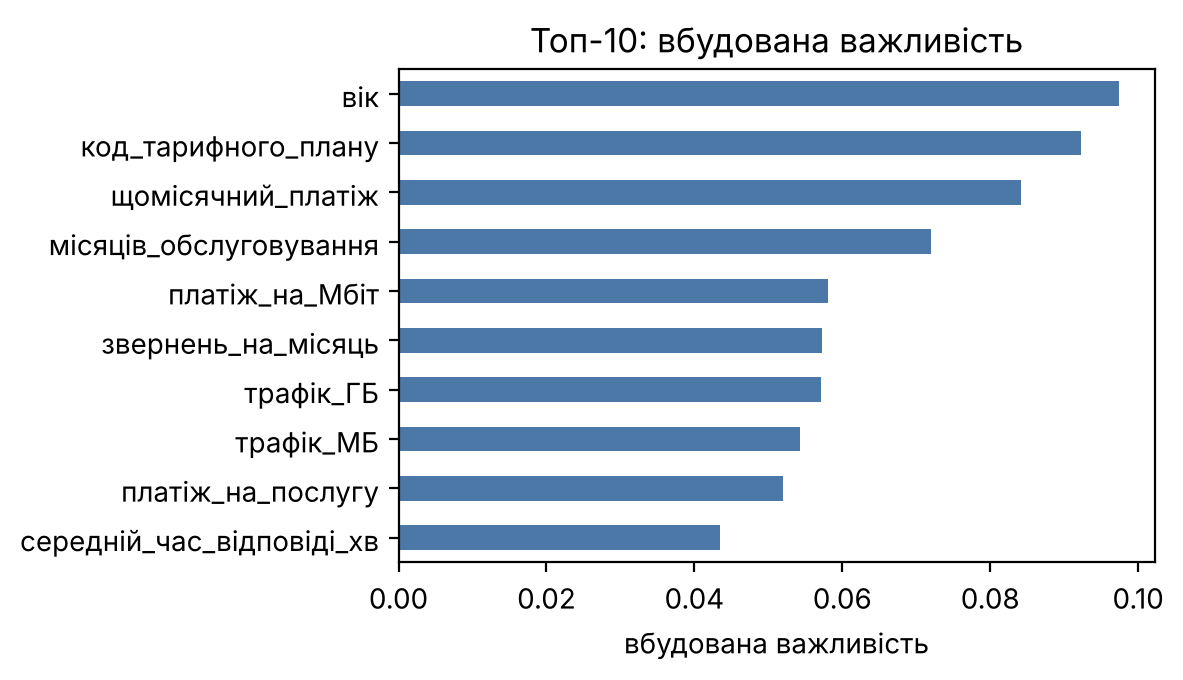

In [ ]:
names = model.named_steps['prep'].get_feature_names_out()

def to_orig(n, cols):
    """'cat__філія_ф-01 центр' -> 'філія'; 'num__missingindicator_x' -> 'x'."""
    n = n.split('__', 1)[1]
    if n.startswith('missingindicator_'):
        n = n[len('missingindicator_'):]
    for c in sorted(cols, key=len, reverse=True):      
        if n == c or n.startswith(c + '_'):
            return c
    return n

raw_imp = pd.Series(model.named_steps['clf'].feature_importances_, index=names)
gini_imp = raw_imp.groupby(lambda n: to_orig(n, FINAL_X.columns)).sum().sort_values(ascending=False)
display(gini_imp.head(10).to_frame('вбудована важливість').round(4))

ax = gini_imp.head(10)[::-1].plot(kind='barh', figsize=(6, 3.5), color='#4C78A8')
ax.set_xlabel('вбудована важливість'); plt.title('Топ-10: вбудована важливість')
plt.tight_layout(); plt.show()

> Вбудована важливість лісу = наскільки ознака «розчищала» (зменшувала змішаність класів) у розбиттях дерев. Одинична кодування розбиває категорію на кілька стовпців (`філія` → 6 стовпців), тому важливості цих «дамі-стовпців» **додаємо назад** до однієї ознаки — інакше категорія з багатьма рівнями виглядала б неважливою лише тому, що її внесок розмазаний.

### Завдання 9.2 — перестановочна важливість

Інший підхід: взяти навчену модель, **перемішати значення однієї ознаки**
у перевірковій частині й подивитись, наскільки впала якість. Впала сильно —
ознака потрібна; не впала — не потрібна.

Рахуйте на **перевірковій** частині: на навчальній перестановочна важливість
показує те саме перенавчання, що й вбудована.

In [31]:
perm = permutation_importance(model, Xte, yte, n_repeats=10,
                              random_state=SEED, scoring='roc_auc')
perm_imp = pd.Series(perm.importances_mean, index=FINAL_X.columns).sort_values(ascending=False)
display(perm_imp.head(10).to_frame('перестановочна важливість'))

,перестановочна важливість
вік,0.070895
щомісячний_платіж,0.043017
місяців_обслуговування,0.020388
трафік_ГБ,0.014559
швидкість_тарифу_Мбіт,0.014182
трафік_МБ,0.006790
кількість_послуг,0.004673
звернень_на_місяць,0.004069
знижка_відсоток,0.003443
тип_підключення,0.002646


> Перестановочна важливість: у **перевірковій** частині перемішуємо значення однієї ознаки (рвемо її зв'язок із ціллю) і дивимось, наскільки впав AUC. Впав сильно — ознака потрібна; не впав — ні. Рахуємо саме на перевірковій, бо на навчальній вона показує перенавчання.

### Завдання 9.3 — ПЕРША ХИБНА ІНТЕРПРЕТАЦІЯ

Порівняйте два списки поруч. Знайдіть ознаку, яка:

* входить у **топ-5 за вбудованою** важливістю;
* має перестановочну важливість **близьку до нуля або від'ємну**.

Така ознака є в кожному варіанті. Знайдіть її, назвіть і поясніть, чому
вбудована важливість її переоцінює.

> **Підказка.** Згадайте, як дерево обирає розбиття. Ознака з великою
> кількістю різних значень дає дереву багато можливих порогів, тож вона
> майже завжди знаходить розбиття, яке трохи зменшує неоднорідність —
> навіть якщо жодного зв'язку з ціллю немає.

In [32]:
cmp_imp = pd.DataFrame({'вбудована': gini_imp, 'перестановочна': perm_imp}).sort_values('вбудована', ascending=False)
display(cmp_imp.head(10).round(4))

,вбудована,перестановочна
вік,0.0973,0.0709
код_тарифного_плану,0.0923,-0.0013
щомісячний_платіж,0.0841,0.0430
місяців_обслуговування,0.0720,0.0204
платіж_на_Мбіт,0.0581,0.0014
звернень_на_місяць,0.0573,0.0041
трафік_ГБ,0.0571,0.0146
трафік_МБ,0.0543,0.0068
платіж_на_послугу,0.0520,-0.0038
середній_час_відповіді_хв,0.0435,-0.0036


>  Дві важливості поруч. Шукаємо ознаку, яка **в топ-5 за вбудованою**, а за перестановочною ≈ 0 або мінус. Це ознака з великою кількістю різних значень (багато можливих порогів) — дерево «ріже» по ній охоче, але реального зв'язку з ціллю нема.

In [33]:
FAKE_IMPORTANT = 'код_тарифного_плану'        # назва ознаки
FAKE_IMPORTANT_WHY = ('у неї 40 різних значень, тож після кодування це 40 стовпців і дерево має безліч '
                      'можливих «розрізів»; випадковий розріз завжди трохи зменшує змішаність класів, '
                      'тому вбудована важливість %.3f (2-е місце), а перестановочна %+.4f (≈ 0)'
                      % (gini_imp['код_тарифного_плану'], perm_imp['код_тарифного_плану']))
assert FAKE_IMPORTANT in FINAL_X.columns and FAKE_IMPORTANT_WHY
print('хибно важлива ознака:', FAKE_IMPORTANT)

хибно важлива ознака: код_тарифного_плану


> 💬 **Коротко (9.3).** Хибно важлива ознака — **`код_тарифного_плану`**: за вбудованою важливістю вона на 2-му місці (~0,09), а за перестановочною ≈ 0 (навіть трохи мінус). Причина: 40 різних значень → безліч можливих розрізів, і дерево знаходить «вдалий» розріз просто випадково.

### Завдання 9.4 — ДРУГА ХИБНА ІНТЕРПРЕТАЦІЯ

У наборі є **дві ознаки, які вимірюють те саме в різних одиницях**.
Знайдіть цю пару (підказка: подивіться на кореляції між числовими ознаками).

Потім перевірте, що з нею робить перестановочна важливість:

1. запишіть важливість обох ознак пари в повній моделі;
2. **приберіть одну** з них, навчіть модель заново і подивіться на важливість
   тієї, що лишилась.

Поясніть, що сталось і чому.

In [34]:
num_cols = [c for c in FINAL_X.columns if str(FINAL_X[c].dtype) != 'category']
corr = FINAL_X[num_cols].corr().abs()
pairs = [(a, b, round(float(corr.loc[a, b]), 4)) for i, a in enumerate(num_cols)
         for b in num_cols[i + 1:] if corr.loc[a, b] > 0.97]
print('пари з |r| > 0.97:', pairs)

пари з |r| > 0.97: [('трафік_ГБ', 'трафік_МБ', 0.9997)]


In [35]:
DUP_PAIR = ['трафік_МБ', 'трафік_ГБ']        # дві ознаки, що вимірюють те саме
assert all(c in FINAL_X.columns for c in DUP_PAIR) and DUP_PAIR[0] != DUP_PAIR[1]

print('у повній моделі:')
for c in DUP_PAIR:
    print('   %-28s %+.4f' % (c, perm_imp[c]))

# приберемо DUP_PAIR[1], навчимо заново на ТОМУ САМОМУ поділі, порахуємо перестановочну
X_nodup = FINAL_X.drop(columns=[DUP_PAIR[1]])
Xtr2, Xte2, ytr2, yte2 = train_test_split(X_nodup, y, test_size=0.3, stratify=y, random_state=SEED)
model2 = make_pipe(X_nodup, RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)).fit(Xtr2, ytr2)
perm2 = permutation_importance(model2, Xte2, yte2, n_repeats=10, random_state=SEED, scoring='roc_auc')
perm2 = pd.Series(perm2.importances_mean, index=X_nodup.columns)
print('\nбез %s:' % DUP_PAIR[1])
print('   %-28s %+.4f   (було %+.4f)' % (DUP_PAIR[0], perm2[DUP_PAIR[0]], perm_imp[DUP_PAIR[0]]))
print('   AUC відкладеної частини без дубля: %.3f (з дублем %.3f)'
      % (roc_auc_score(yte2, model2.predict_proba(Xte2)[:, 1]), auc_hold))

у повній моделі:
   трафік_МБ                    +0.0068
   трафік_ГБ                    +0.0146



без трафік_ГБ:
   трафік_МБ                    +0.0220   (було +0.0068)
   AUC відкладеної частини без дубля: 0.819 (з дублем 0.812)


In [36]:
DUP_EXPLANATION = (
    'трафік_МБ і трафік_ГБ — одна й та сама величина в різних одиницях (r ≈ 1): коли перемішати одну, '
    'модель бере інформацію з другої, тому в повній моделі обидві виглядають слабкими (%+.4f і %+.4f). '
    'Коли прибрати трафік_ГБ, важливість трафік_МБ зросла з %+.4f до %+.4f (у %.1f раза): ознака потрібна, '
    'її просто «страхувала» копія. Це не вада методу: він чесно відповідає «що буде без цієї колонки», '
    'а інформація лишається у двійника.'
    % (perm_imp['трафік_МБ'], perm_imp['трафік_ГБ'], perm_imp['трафік_МБ'], perm2['трафік_МБ'],
       perm2['трафік_МБ'] / perm_imp['трафік_МБ']))
assert DUP_EXPLANATION
print(DUP_EXPLANATION)

трафік_МБ і трафік_ГБ — одна й та сама величина в різних одиницях (r ≈ 1): коли перемішати одну, модель бере інформацію з другої, тому в повній моделі обидві виглядають слабкими (+0.0068 і +0.0146). Коли прибрати трафік_ГБ, важливість трафік_МБ зросла з +0.0068 до +0.0220 (у 3.2 раза): ознака потрібна, її просто «страхувала» копія. Це не вада методу: він чесно відповідає «що буде без цієї колонки», а інформація лишається у двійника.


>  Пара-двійник: **`трафік_МБ` і `трафік_ГБ`** (те саме в різних одиницях, r ≈ 1). У повній моделі обидві виглядають слабкими, бо кожна «страхує» іншу. Прибрали ГБ → важливість МБ зросла ~у 3 рази (0,007 → 0,022). Висновок: «важливість мала» ≠ «ознака непотрібна».

> **Що тут сталося.** Перестановочна важливість відповідає на питання
> «наскільки модель погіршиться **без цієї ознаки**». Коли та сама інформація
> є у двох колонках, перемішування однієї нічого не ламає: модель бере її
> з другої. Обидві виглядають непотрібними — хоча разом вони важливі.
>
> Це не вада методу, а точна відповідь на поставлене питання. Вада —
> в інтерпретації «важливість нуль, отже ознаку можна викинути».

---
## 10. Графіки часткової залежності

Важливість каже, **наскільки** ознака потрібна. Вона не каже, **як саме**
ознака впливає: більше — ризикованіше чи навпаки.

**Графік часткової залежності (PDP)** будується так: беремо всю вибірку,
підставляємо всім клієнтам одне й те саме значення ознаки, усереднюємо
прогноз; повторюємо для сітки значень.

### Завдання 10.1

Побудуйте PDP для трьох найважливіших **числових** ознак за перестановочною
важливістю. Для кожної скажіть словами, що означає форма кривої.

PDP для: ['вік', 'щомісячний_платіж', 'місяців_обслуговування']


вік                      n=360 (пропусків у ознаці: 0)  ризик від 0.25 до 0.45


щомісячний_платіж        n=348 (пропусків у ознаці: 12)  ризик від 0.25 до 0.43


місяців_обслуговування   n=360 (пропусків у ознаці: 0)  ризик від 0.23 до 0.35


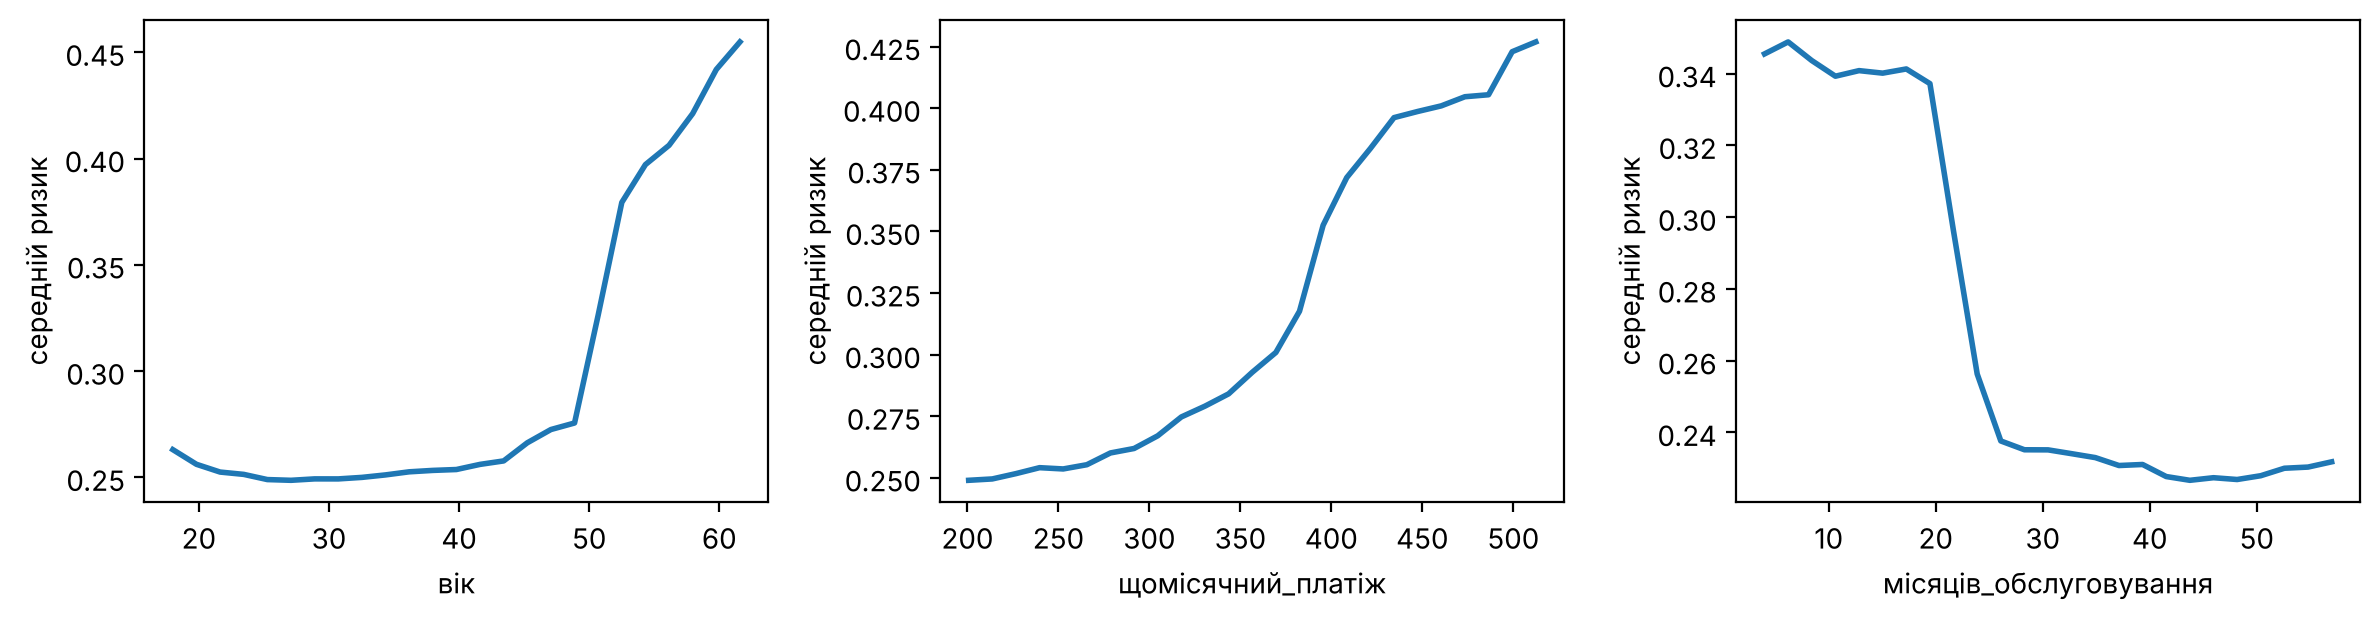

In [ ]:
from sklearn.inspection import PartialDependenceDisplay

top_num = [c for c in perm_imp.index if c in num_cols][:3]
print('PDP для:', top_num)
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
for a_, c in zip(ax, top_num):
    sub = Xte[Xte[c].notna()]           
    r = partial_dependence(model, sub, [c], kind='average', grid_resolution=25)
    a_.plot(r['grid_values'][0], r['average'][0], lw=2)
    a_.set_xlabel(c); a_.set_ylabel('середній ризик')
    print('%-24s n=%d (пропусків у ознаці: %d)  ризик від %.2f до %.2f'
          % (c, len(sub), len(Xte) - len(sub), r['average'][0].min(), r['average'][0].max()))
plt.tight_layout(); plt.show()

>  PDP (графік часткової залежності) показує **форму** впливу: беремо всіх клієнтів, підставляємо всім одне значення ознаки, усереднюємо ризик, повторюємо по сітці значень. Бачимо, у який бік і як саме ознака змінює *середній* прогноз. Ознаки з пропусками не беремо — для них сітка порожня.

### Завдання 10.2 — немонотонна залежність

Серед ознак є така, у якої PDP **не монотонний**: ризик спадає, а потім
знову зростає (або навпаки). Знайдіть її.

Лінійна модель такої залежності не бачить **за побудовою**: вона може лише
зростати або лише спадати. Перевірте це: порівняйте PDP лісу й логістичної
регресії на тій самій ознаці, на одному рисунку.

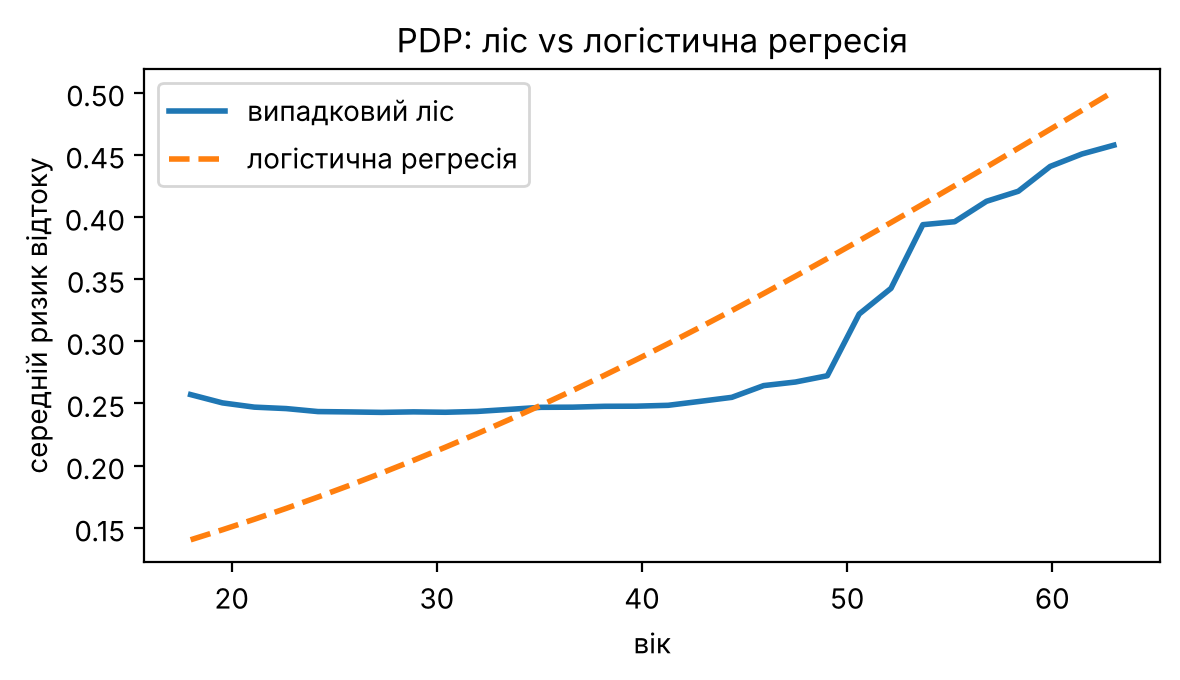

мінімум ризику лісу при вік = 27.31
ліс:  [0.257 0.243 0.243 0.247 0.252 0.272 0.396 0.451]  при [18. 24. 30. 37. 43. 49. 55. 61.]
логіст.: [0.14  0.175 0.215 0.26  0.311 0.367 0.425 0.486]


In [ ]:
NONLINEAR_FEATURE = 'вік'
assert NONLINEAR_FEATURE in FINAL_X.columns

def pd_curve(m, X, col):
    r = partial_dependence(m, X, [col], kind='average', grid_resolution=30)
    return r['grid_values'][0], r['average'][0]

lin_model = make_pipe(FINAL_X, logreg()).fit(Xtr, ytr)
gx, gy_rf = pd_curve(model, FINAL_X, NONLINEAR_FEATURE)
_, gy_lr = pd_curve(lin_model, FINAL_X, NONLINEAR_FEATURE)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(gx, gy_rf, label='випадковий ліс', lw=2)
ax.plot(gx, gy_lr, label='логістична регресія', lw=2, ls='--')
ax.set_xlabel(NONLINEAR_FEATURE); ax.set_ylabel('середній ризик відтоку'); ax.legend()
plt.title('PDP: ліс vs логістична регресія'); plt.tight_layout(); plt.show()
x_min = float(gx[int(np.argmin(gy_rf))])
print('мінімум ризику лісу при %s = %.2f' % (NONLINEAR_FEATURE, x_min))
print('ліс: ', np.round(gy_rf[::4], 3), ' при', np.round(gx[::4], 0))
print('логіст.:', np.round(gy_lr[::4], 3))

>  Немонотонна ознака — **`вік`**: ризик мінімальний у 25–40 років і різко росте після ~50. Логістична регресія може лише піднімати/опускати пряму, тому на графіку вона йде «косою лінією» і промахується (особливо для молодих).

In [39]:
NONLINEAR_MEANING = ('вік: найнижчий ризик у клієнтів ~%.0f-40 років; у наймолодших він трохи вищий, '
                     'а після ~50 років різко зростає (з ~0.25 до ~0.45) — крива «чаша», а не пряма' % x_min)
NONLINEAR_FIX = ('квадрат відхилення віку від точки мінімуму (вік - %.0f)^2: лінійна модель вміє лише '
                 'зростати або лише спадати, а ця ознака дає їй «чашу»' % x_min)
assert NONLINEAR_MEANING and NONLINEAR_FIX
print(NONLINEAR_MEANING)
print(NONLINEAR_FIX)

вік: найнижчий ризик у клієнтів ~27-40 років; у наймолодших він трохи вищий, а після ~50 років різко зростає (з ~0.25 до ~0.45) — крива «чаша», а не пряма
квадрат відхилення віку від точки мінімуму (вік - 27)^2: лінійна модель вміє лише зростати або лише спадати, а ця ознака дає їй «чашу»


### Завдання 10.2б — замкніть цикл

Пояснення моделі має **повертатись у підготовку даних**. PDP показав форму —
тепер побудуйте ознаку цієї форми і виміряйте, що вона дала.

Зробіть це для **логістичної регресії**, а не для лісу: ліс цю форму і так
бачив, а лінійна модель — ні. Порівняння має бути парним.

In [ ]:
x_min = float(gx[int(np.argmin(gy_rf))])
print('мінімум ризику при', round(x_min, 2))

Xq = FINAL_X.copy()
Xq['квадрат_відхилення'] = (Xq[NONLINEAR_FEATURE] - x_min) ** 2

auc_lin = cross_val_score(make_pipe(FINAL_X, logreg()), FINAL_X, y, cv=cv, scoring='roc_auc')
auc_lin_q = cross_val_score(make_pipe(Xq, logreg()), Xq, y, cv=cv, scoring='roc_auc')
m_q, h_q = paired(auc_lin, auc_lin_q)
print('логістична без ознаки: AUC %.3f ± %.3f' % (auc_lin.mean(), auc_lin.std()))
print('логістична з ознакою : AUC %.3f ± %.3f' % (auc_lin_q.mean(), auc_lin_q.std()))
print('приріст: %+0.4f ± %.4f   %s' % (m_q, h_q, 'значуще' if abs(m_q) > h_q else 'у межах шуму'))

мінімум ризику при 27.31


логістична без ознаки: AUC 0.812 ± 0.021
логістична з ознакою : AUC 0.830 ± 0.019
приріст: +0.0175 ± 0.0135   значуще


>  Беремо мінімум з графіка (~27 років), додаємо ознаку «(вік − 27)²» — це «чаша». Логістична регресія з нею ліпша на **+0,018** AUC, і цей приріст значущий (більший за свою похибку). Тобто пояснення моделі повернулося в підготовку даних і реально допомогло.

In [41]:
QUAD_GAIN = float(m_q)     # приріст AUC лінійної моделі від нової ознаки
assert QUAD_GAIN is not None
print('приріст від сконструйованої ознаки: %+.4f' % QUAD_GAIN)

приріст від сконструйованої ознаки: +0.0175


### Завдання 10.3 — ТРЕТЯ ХИБНА ІНТЕРПРЕТАЦІЯ

PDP **усереднює по всій вибірці**. Якщо ознака діє на різні групи клієнтів
по-різному, усереднення це приховає: протилежні ефекти взаємно погасяться,
і крива вийде майже пласкою.

Перевірте це на парі «знижка — стаж обслуговування».

1. Побудуйте звичайний PDP для `знижка_відсоток` по всій вибірці.
2. Побудуйте **ICE** (`kind='individual'`) — по кривій на кожного клієнта.
   Подивіться, чи всі криві йдуть в один бік.
3. Побудуйте PDP для `знижка_відсоток` **окремо** на двох підвибірках:
   клієнти зі стажем до 24 місяців і понад 24 місяці.

> **Важливо.** PDP і ICE рахуйте на **повній** матриці `FINAL_X`,
> а не на `Xte`. Це опитування моделі, а не оцінювання якості, тож
> використовувати всі рядки коректно — а на 30 % рядків підгрупи виходять
> замалі й криві стають шумними.

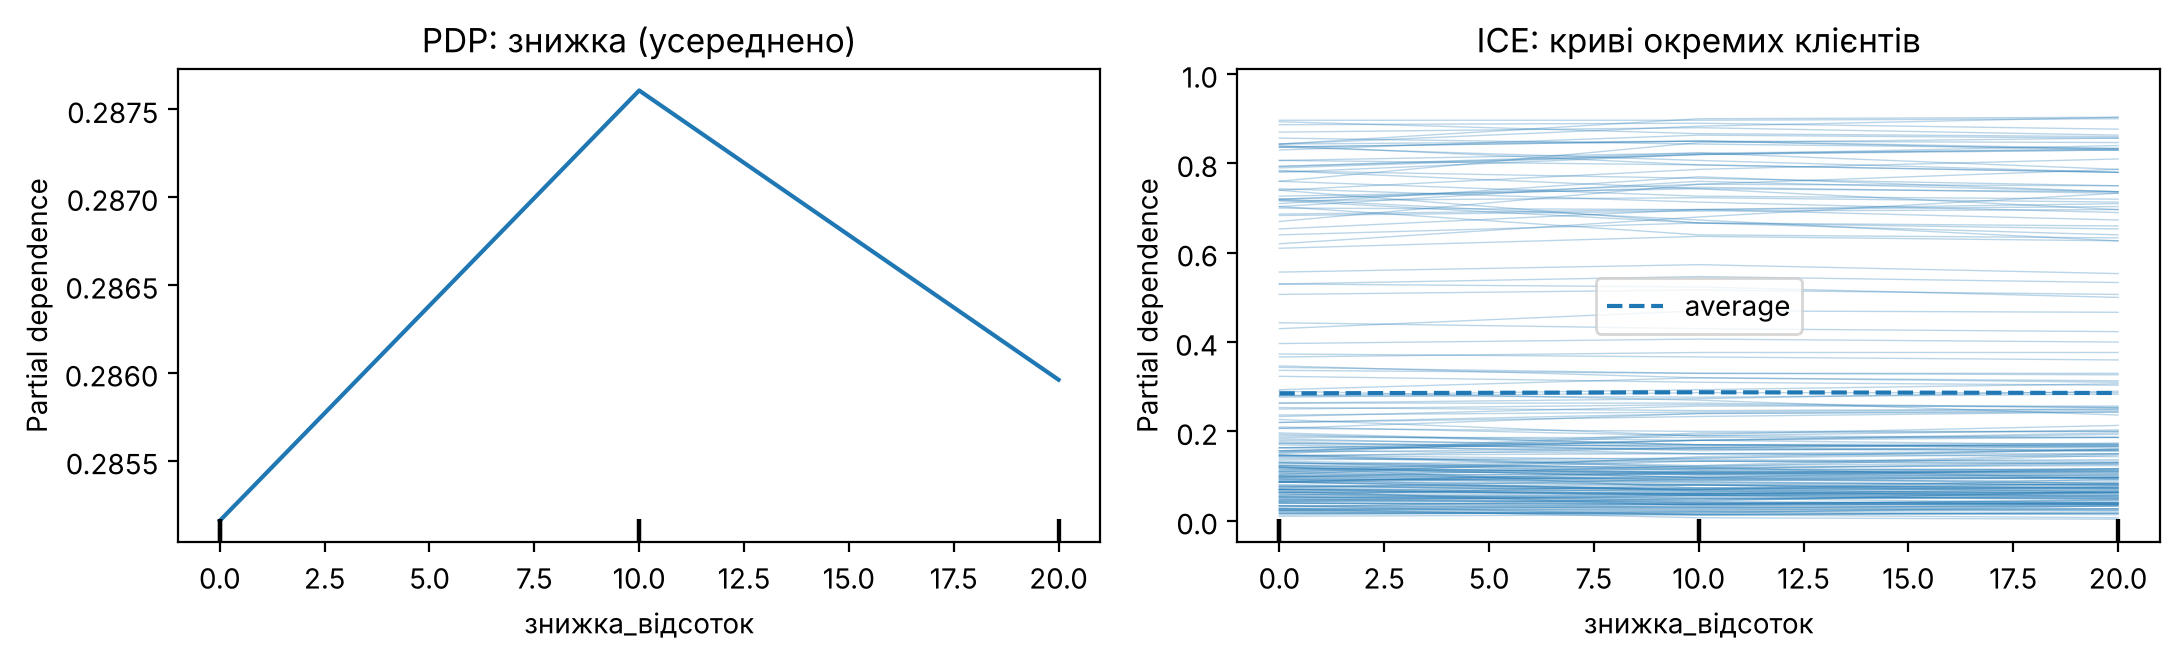

середня зміна ризику 0 -> 20 %: +0.001
ризик ЗРОС більше ніж на 2 п.п. у 21 % клієнтів, ЗНИЗИВСЯ — у 20 %


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
PartialDependenceDisplay.from_estimator(model, FINAL_X, ['знижка_відсоток'], kind='average', ax=ax[0])
ax[0].set_title('PDP: знижка (усереднено)')
PartialDependenceDisplay.from_estimator(model, FINAL_X, ['знижка_відсоток'], kind='both',
                                        subsample=200, random_state=SEED, ax=ax[1])
ax[1].set_title('ICE: криві окремих клієнтів')
plt.tight_layout(); plt.show()

ice = partial_dependence(model, FINAL_X, ['знижка_відсоток'], kind='individual')['individual'][0]
delta = ice[:, -1] - ice[:, 0]
print('середня зміна ризику 0 -> 20 %%: %+.3f' % delta.mean())
print('ризик ЗРОС більше ніж на 2 п.п. у %.0f %% клієнтів, ЗНИЗИВСЯ — у %.0f %%'
      % (100 * (delta > 0.02).mean(), 100 * (delta < -0.02).mean()))

>  PDP знижки по всіх клієнтах майже плаский (зміна 0 → 20 % ≈ +0,001). Але ICE (по кривій на кожного) показує, що ~21 % клієнтів реагують зростанням ризику, а ~20 % — спадом: усереднення «погасило» протилежні ефекти.

стаж до 24 міс.      [0.357 0.366 0.364]


стаж понад 24 міс.   [0.179 0.171 0.17 ]


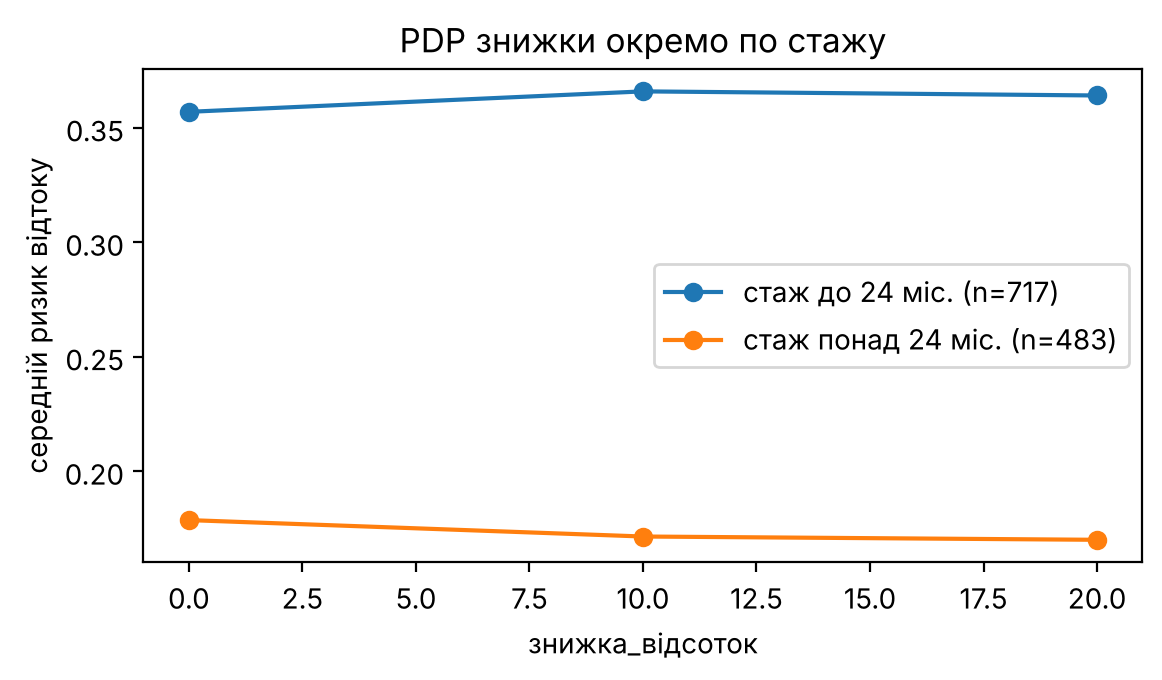

In [43]:
mask = FINAL_X['місяців_обслуговування'] <= 24
fig, ax = plt.subplots(figsize=(6, 3.5))
for lab, m_ in [('стаж до 24 міс.', mask), ('стаж понад 24 міс.', ~mask)]:
    r = partial_dependence(model, FINAL_X[m_], ['знижка_відсоток'], kind='average')
    ax.plot(r['grid_values'][0], r['average'][0], marker='o', label='%s (n=%d)' % (lab, m_.sum()))
    print('%-20s' % lab, np.round(r['average'][0], 3))
ax.set_xlabel('знижка_відсоток'); ax.set_ylabel('середній ризик відтоку'); ax.legend()
plt.title('PDP знижки окремо по стажу'); plt.tight_layout(); plt.show()

> PDP окремо по стажу.  Чесно: ліс майже не відтворив різницю між групами (лінії майже пласкі), хоча в сирих даних вона велика. Тобто це «питання до моделі»: ліс із ~25 ознаками «втопив» цей сигнал. Головний доказ — таблиця по сирих даних нижче.

### Завдання 10.3б — звірка з сирими даними

Перш ніж вірити графіку, перевірте його по сирій таблиці: порахуйте
**емпіричну** частку відтоку за розміром знижки окремо в кожній групі стажу.
Модель має відтворювати ту саму картину. Якщо не відтворює — питання
не до PDP, а до моделі.

In [44]:
grp = np.where(raw['місяців_обслуговування'] <= 24, 'до 24 міс.', 'понад 24 міс.')
emp = raw.assign(стаж=grp).pivot_table(index='знижка_відсоток', columns='стаж', values=TARGET,
                                       aggfunc=['mean', 'size']).round(3)
display(emp)

mean                     size              
стаж            до 24 міс. понад 24 міс. до 24 міс. понад 24 міс.
знижка_відсоток                                                  
0                    0.296         0.212        307           189
10                   0.423         0.138        220           167
20                   0.458         0.071        190           127

> ** Звірка з сирими даними: у новачків (до 24 міс.) відтік **росте** зі знижкою (29,6 → 42,3 → 45,8 %), у давніх клієнтів **падає** (21,2 → 13,8 → 7,1 %). Розміри груп від 127 до 307 — достатньо, щоб не списати на випадковість.

In [45]:
INTERACTION_FOUND = (
    'У клієнтів зі стажем до 24 міс. відтік РОСТЕ разом зі знижкою: 29.6 %% (0 %%) -> 42.3 %% (10 %%) -> 45.8 %% (20 %%); '
    'у клієнтів зі стажем понад 24 міс. він ПАДАЄ: 21.2 %% -> 13.8 %% -> 7.1 %%. Протилежні ефекти гасять один одного, '
    'тому звичайний PDP майже плаский (зміна %+.3f), а ICE показує: ризик виріс у %.0f %% клієнтів і впав у %.0f %%.'
    % (delta.mean(), 100 * (delta > 0.02).mean(), 100 * (delta < -0.02).mean()))
BUSINESS_ACTION = ('не пропонувати знижку всім підряд: давнім клієнтам (понад 24 міс.) вона збігається з низьким відтоком, '
                   'а для новачків — ні (можливо, її давали тим, хто вже збирався піти); це кореляція, тож перед '
                   'рішенням треба A/B-тест на новачках')
assert INTERACTION_FOUND and BUSINESS_ACTION
print(INTERACTION_FOUND)
print(BUSINESS_ACTION)

У клієнтів зі стажем до 24 міс. відтік РОСТЕ разом зі знижкою: 29.6 % (0 %) -> 42.3 % (10 %) -> 45.8 % (20 %); у клієнтів зі стажем понад 24 міс. він ПАДАЄ: 21.2 % -> 13.8 % -> 7.1 %. Протилежні ефекти гасять один одного, тому звичайний PDP майже плаский (зміна +0.001), а ICE показує: ризик виріс у 21 % клієнтів і впав у 20 %.
не пропонувати знижку всім підряд: давнім клієнтам (понад 24 міс.) вона збігається з низьким відтоком, а для новачків — ні (можливо, її давали тим, хто вже збирався піти); це кореляція, тож перед рішенням треба A/B-тест на новачках


>  Знижка діє у двох групах у протилежні боки, тому «в середньому» нічого не видно. Дія для бізнесу: не роздавати знижки всім, давати давнім клієнтам; для новачків спершу перевірити A/B-тестом (це кореляція, а не доведена причина).

> **Що тут сталося.** PDP відповідає на питання «як змінюється
> **середній** прогноз». Якщо ефект різноспрямований, середнє близьке до нуля
> при сильних ефектах у кожній групі. ICE показує окремі криві й робить
> розбіжність видимою; PDP по підгрупах показує її кількісно.

---
## 11. Значення Шеплі

Важливість і PDP описують модель **загалом**. Відділу утримання потрібне
інше: чому **цей** клієнт отримав оцінку 0,8.

**Значення Шеплі** (SHAP) розкладають прогноз для одного об'єкта на внески
окремих ознак так, щоб сума внесків плюс базовий рівень дорівнювала самому
прогнозу. Ідея запозичена з теорії кооперативних ігор: внесок гравця —
це його середній приріст до результату по всіх можливих складах команди.

### Завдання 11.1

Порахуйте значення Шеплі для вашої моделі на перевірковій частині.

> `TreeExplainer` працює з деревами і хоче **числову матрицю**, тому
> подавайте йому вже перетворені дані: `model.named_steps['prep'].transform(Xte)`.

In [46]:
import shap

prep = model.named_steps['prep']
clf = model.named_steps['clf']
Xte_t = prep.transform(Xte)
feat_names = prep.get_feature_names_out()

SAMPLE = min(300, Xte_t.shape[0])      # щоб рахувалось за секунди
expl = shap.TreeExplainer(clf)
sv = expl.shap_values(Xte_t[:SAMPLE])
sv1 = sv[..., 1] if (hasattr(sv, 'ndim') and sv.ndim == 3) else sv
print('матриця значень Шеплі:', np.shape(sv1))

матриця значень Шеплі: (300, 88)


>  Значення Шеплі (SHAP) розкладають прогноз для **одного клієнта** на внески ознак: базовий рівень (середній ризик ≈ 0,29) + внески = його ризик. Рахуємо на 300 клієнтах з перевіркової частини.

### Завдання 11.2 — зведений графік

Побудуйте `beeswarm` (`shap.summary_plot`). Прочитайте з нього дві речі,
яких **не дає** стовпчикова діаграма важливості:

* у який бік діє ознака (колір — значення ознаки, вісь — внесок);
* чи однаковий цей напрям для всіх клієнтів.

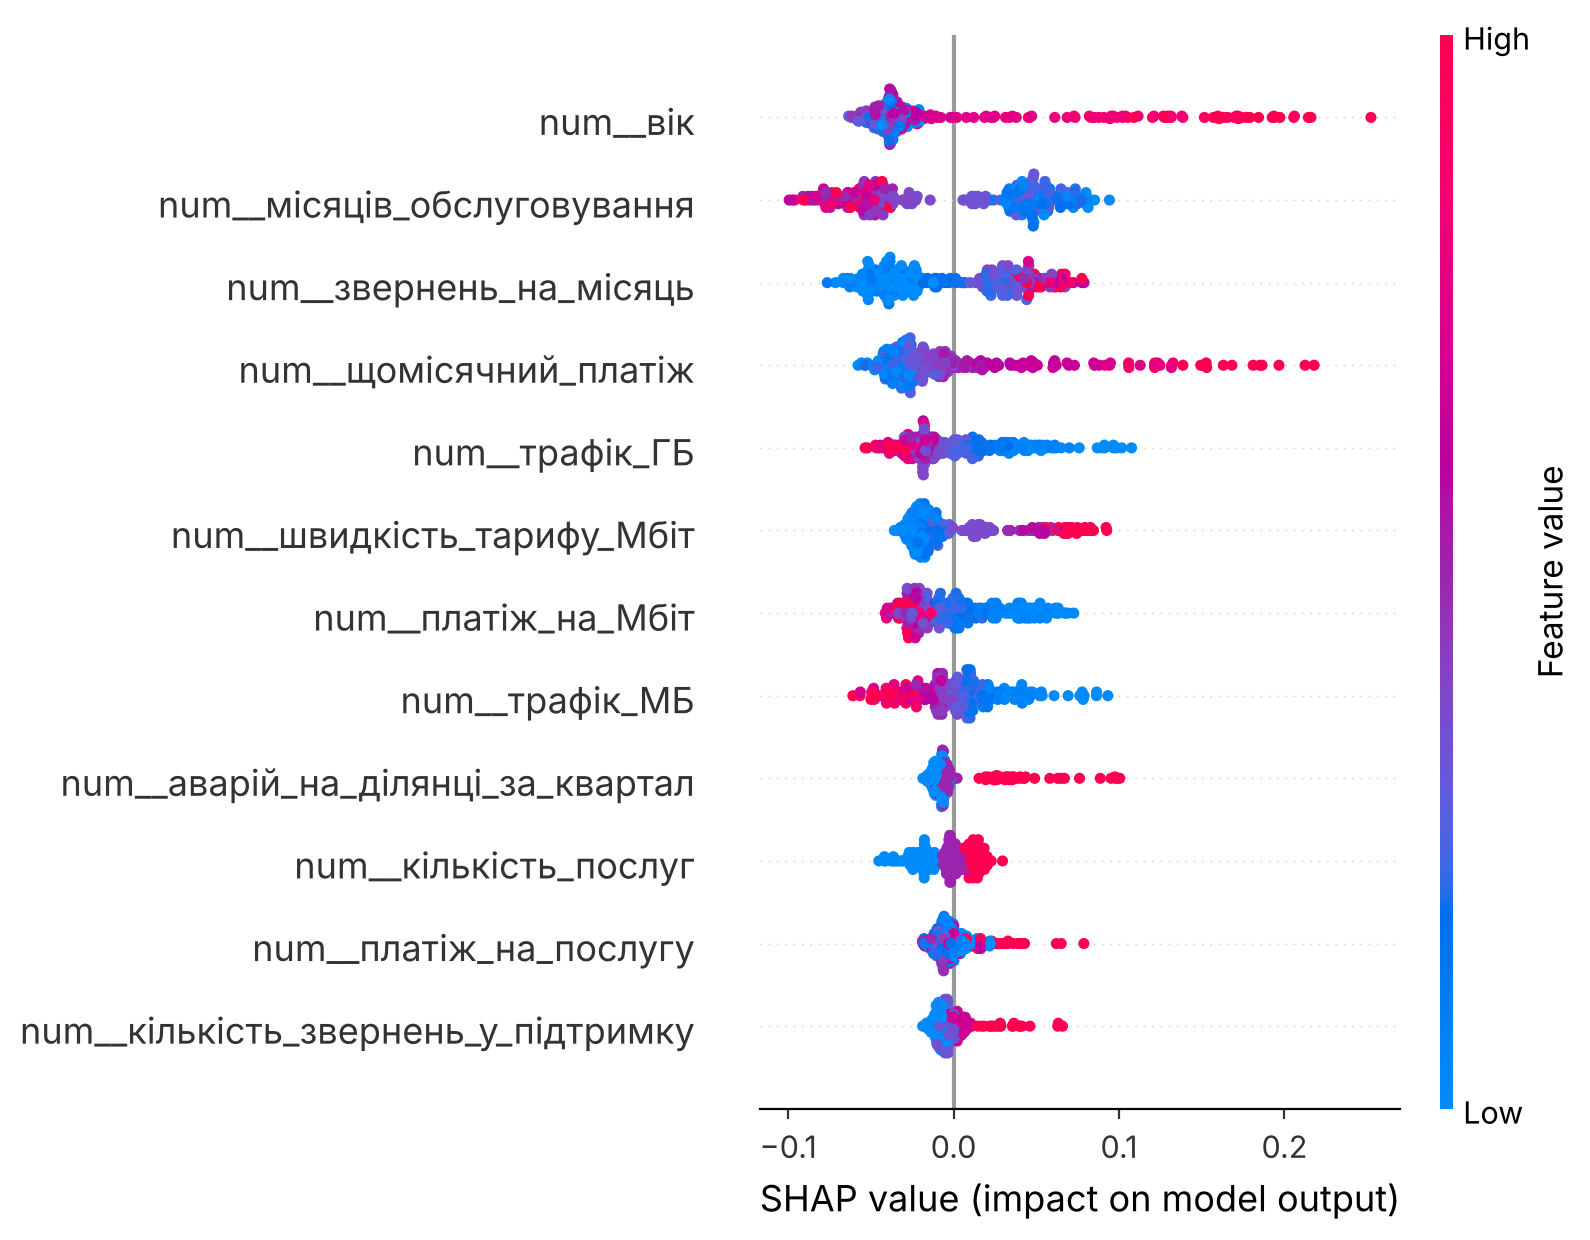

,середній |внесок Шеплі|
вік,0.0552
місяців_обслуговування,0.0518
звернень_на_місяць,0.0383
щомісячний_платіж,0.0380
код_тарифного_плану,0.0290
трафік_ГБ,0.0269


In [ ]:
shap.summary_plot(sv1, Xte_t[:SAMPLE], feature_names=feat_names, max_display=12)

mean_abs = pd.Series(np.abs(sv1).mean(axis=0), index=feat_names)
mean_abs = mean_abs.groupby(lambda n: to_orig(n, FINAL_X.columns)).sum().sort_values(ascending=False)
display(mean_abs.head(6).round(4).to_frame('середній |внесок Шеплі|'))

>  Beeswarm: кожна точка — клієнт; вісь X — внесок (праворуч підвищує ризик), колір — значення ознаки (червоне = велике). Звідси видно **напрям** (наприклад, великий вік і великий платіж — праворуч) і чи однаковий він для всіх. За середнім модулем внеску лідери: вік (0,055), стаж (0,052), звернень на місяць (0,038), платіж (0,038).

### Завдання 11.3 — пояснення для одного клієнта

Відділ утримання телефонує конкретній людині. Візьміть клієнта з
**найвищою** оцінкою ризику і поясніть його прогноз: які три ознаки
внесли найбільше і в який бік.

Напишіть пояснення **мовою, якою його можна прочитати менеджерові**, —
без назв стовпців і без слова «модель».

In [ ]:
idx = int(np.argmax(model.predict_proba(Xte)[:SAMPLE, 1]))
print('ризик клієнта: %.3f' % model.predict_proba(Xte)[:SAMPLE, 1][idx])

contrib = pd.Series(sv1[idx], index=feat_names)
top3 = contrib.abs().sort_values(ascending=False).head(3).index
base_val = float(np.ravel(expl.expected_value)[-1])
print('базовий рівень (середній ризик): %.3f' % base_val)
orig_row = Xte.iloc[idx]
for n in top3:
    c = to_orig(n, FINAL_X.columns)
    print('%-45s внесок %+.3f   значення у клієнта: %s' % (n, contrib[n], orig_row[c]))

ризик клієнта: 0.860
базовий рівень (середній ризик): 0.285
num__щомісячний_платіж                        внесок +0.133   значення у клієнта: 649.42
num__вік                                      внесок +0.109   значення у клієнта: 60.0
num__швидкість_тарифу_Мбіт                    внесок +0.080   значення у клієнта: 1000.0


In [49]:
EXPLANATION_FOR_MANAGER = (
    'Цей клієнт піде з імовірністю близько 86 % (типовий клієнт — близько 29 %). Три головні причини: '
    'він платить за інтернет 650 грн на місяць — набагато більше, ніж більшість; йому 60 років, а в цій віковій '
    'групі клієнти відходять помітно частіше; і він на найшвидшому, найдорожчому тарифі (1000 Мбіт). '
    'Разом ці три речі піднімають ризик приблизно на 32 відсоткові пункти, решта дає ще додаток.')
assert EXPLANATION_FOR_MANAGER
print(EXPLANATION_FOR_MANAGER)

Цей клієнт піде з імовірністю близько 86 % (типовий клієнт — близько 29 %). Три головні причини: він платить за інтернет 650 грн на місяць — набагато більше, ніж більшість; йому 60 років, а в цій віковій групі клієнти відходять помітно частіше; і він на найшвидшому, найдорожчому тарифі (1000 Мбіт). Разом ці три речі піднімають ризик приблизно на 32 відсоткові пункти, решта дає ще додаток.


>  Найризикованіший клієнт: ризик 0,86 при базовому 0,29. Три головні внески: платіж 649 грн (+0,133), вік 60 (+0,109), тариф 1000 Мбіт (+0,080). Текст для менеджера написаний без назв стовпців і без слова «модель».

### Завдання 11.4 — ЧЕТВЕРТА ХИБНА ІНТЕРПРЕТАЦІЯ

Менеджер читає ваше пояснення і каже:

> «Зрозуміло. Значення Шеплі кажуть, що ризик тягне нагору
> **{ознака}**. Змінимо її — і клієнт лишиться».

Це найпоширеніша і найдорожча помилка в інтерпретації. Значення Шеплі
показують, **як модель користується ознакою**, а не **що станеться, якщо
ознаку змінити**. Це різні твердження, і друге з них вимагає причинного
висновку, якого в даних немає.

Наведіть із **свого** набору конкретний приклад: ознака з великим внеском,
втручання в яку нічого не дасть. Поясніть чому.

In [50]:
SHAP_NOT_CAUSAL_FEATURE = 'вік'
SHAP_NOT_CAUSAL_WHY = ('вік має один із найбільших внесків (у найризикованішого клієнта +0.11), але змінити вік '
                       'клієнта неможливо; Шеплі кажуть лише «модель користується віком» (люди 50+ частіше йдуть), '
                       'а не «зміна віку зменшить відтік» — причину відтоку тут може приховувати щось інше '
                       '(звички, тарифи, які обирають літні люди)')
assert SHAP_NOT_CAUSAL_FEATURE and SHAP_NOT_CAUSAL_WHY
print(SHAP_NOT_CAUSAL_FEATURE, '—', SHAP_NOT_CAUSAL_WHY)

вік — вік має один із найбільших внесків (у найризикованішого клієнта +0.11), але змінити вік клієнта неможливо; Шеплі кажуть лише «модель користується віком» (люди 50+ частіше йдуть), а не «зміна віку зменшить відтік» — причину відтоку тут може приховувати щось інше (звички, тарифи, які обирають літні люди)


>  `вік` — великий внесок, але вплинути на нього неможливо. Шеплі кажуть, **як модель користується ознакою**, а не **що буде, якщо її змінити**. Це різні твердження.

> **Орієнтир.** Ознаки бувають трьох видів: ті, на які можна вплинути
> (знижка, швидкість тарифу, швидкість реакції підтримки); ті, на які
> вплинути не можна (вік, місто, стаж); і ті, що є **наслідком** чогось
> іншого. Дія має сенс лише для першого виду — і лише якщо у вас є підстави
> вважати зв'язок причинним, а не збігом.

---
## 12. Зведення: чотири хибні інтерпретації

### Завдання 12.1

Заповніть таблицю своїми знахідками. Це головний результат другої частини.

In [51]:
mistakes = pd.DataFrame([
    {'№': 1, 'інструмент': 'вбудована важливість',
     'хибний висновок': 'ознака важлива, бо дерево часто по ній ріже',
     'ознака у вашому наборі': FAKE_IMPORTANT,
     'чим перевірити': 'перестановочна важливість на перевірковій частині'},
    {'№': 2, 'інструмент': 'перестановочна важливість',
     'хибний висновок': 'важливість нуль, отже ознаку можна викинути',
     'ознака у вашому наборі': ' + '.join(DUP_PAIR),
     'чим перевірити': 'прибрати одну з пари й переобчислити'},
    {'№': 3, 'інструмент': 'PDP',
     'хибний висновок': 'крива пласка, отже ознака не діє',
     'ознака у вашому наборі': 'знижка_відсоток',
     'чим перевірити': 'ICE або PDP окремо по підгрупах'},
    {'№': 4, 'інструмент': 'значення Шеплі',
     'хибний висновок': 'великий внесок, отже зміна ознаки змінить результат',
     'ознака у вашому наборі': SHAP_NOT_CAUSAL_FEATURE,
     'чим перевірити': 'питання, чи можна на цю ознаку вплинути взагалі'},
]).set_index('№')
display(mistakes)

,інструмент,хибний висновок,ознака у вашому наборі,чим перевірити
№,,,,
1,вбудована важливість,"ознака важлива, бо дерево часто по ній ріже",код_тарифного_плану,перестановочна важливість на перевірковій частині
2,перестановочна важливість,"важливість нуль, отже ознаку можна викинути",трафік_МБ + трафік_ГБ,прибрати одну з пари й переобчислити
3,PDP,"крива пласка, отже ознака не діє",знижка_відсоток,ICE або PDP окремо по підгрупах
4,значення Шеплі,"великий внесок, отже зміна ознаки змінить резу...",вік,"питання, чи можна на цю ознаку вплинути взагалі"


>  Зведена таблиця чотирьох хибних інтерпретацій на моїх даних: код_тарифного_плану (вбудована), трафік_МБ + трафік_ГБ (перестановочна), знижка_відсоток (PDP), вік (Шеплі).

### Завдання 12.2 — п'ята, яку ви знайшли самі

Знайдіть у своєму аналізі ще один випадок, де пояснення можна прочитати
неправильно. Це може бути що завгодно: ознака-наслідок, що пройшла фільтри;
категорія з трьох спостережень і великим внеском; ознака, яка корелює
з артефактом збору. Опишіть його.

In [ ]:
_xs = {c: roc_auc_score(source, FINAL_X[c].cat.codes if str(FINAL_X[c].dtype) == 'category'
                        else FINAL_X[c].fillna(FINAL_X[c].median())) for c in
       ['швидкість_тарифу_Мбіт', 'автоплатіж', 'тип_підключення']}
_xs = {k: max(v, 1 - v) for k, v in _xs.items()}
FIFTH_MISTAKE = (
    'Дату підключення я викинула, але артефакт збору лишився в ознаках-«сусідах»: за чесними ознаками період '
    'передбачається з AUC %.3f, зокрема швидкість_тарифу_Мбіт сама дає AUC %.3f. Тому великий внесок швидкості '
    'тарифу в Шеплі/важливості частково означає «клієнт з нового періоду зі зміненими правилами обліку», '
    'а не «швидкий тариф змушує йти» — читати це як причину не можна.' % (auc_src.mean(), _xs['швидкість_тарифу_Мбіт']))
assert FIFTH_MISTAKE and len(FIFTH_MISTAKE) > 40, 'опишіть докладніше'
print(FIFTH_MISTAKE)

Дату підключення я викинула, але артефакт збору лишився в ознаках-«сусідах»: за чесними ознаками період передбачається з AUC 0.751, зокрема швидкість_тарифу_Мбіт сама дає AUC 0.642. Тому великий внесок швидкості тарифу в Шеплі/важливості частково означає «клієнт з нового періоду зі зміненими правилами обліку», а не «швидкий тариф змушує йти» — читати це як причину не можна.


>  П'ята помилка, знайдена самостійно: я викинула дату підключення, але артефакт лишився в «сусідніх» ознаках (швидкість тарифу, тип підключення, автоплатіж) — вони досі «видають» період з AUC 0,751. Тож внесок швидкості тарифу не можна читати як причину.

---
## 13. Підсумкова модель і карта дій

### Завдання 13.1

Відділ утримання може обдзвонити **100 клієнтів на тиждень** — не більше.
Отже вам потрібна не «модель узагалі», а список зі ста прізвищ.

Відсортуйте перевіркову частину за оцінкою ризику спадно, візьміть перші 100
і порахуйте: скільки з них справді пішли? Порівняйте з тим, скільки ви
знайшли б, обираючи 100 клієнтів навмання.

In [ ]:
TOP_N = 100
p_te = model.predict_proba(Xte)[:, 1]
order = np.argsort(-p_te)[:TOP_N]                   
rate_top = float(yte.iloc[order].mean())
rate_all = float(yte.mean())
lift = rate_top / rate_all
print('у топ-%d пішло %.0f (%.1f %%), у всій перевірці %.1f %% -> навмання було б ~%.0f'
      % (TOP_N, yte.iloc[order].sum(), 100 * rate_top, 100 * rate_all, TOP_N * rate_all))
print('lift = %.2f;  AUC на відкладеній частині = %.3f' % (lift, auc_hold))

у топ-100 пішло 64 (64.0 %), у всій перевірці 28.6 % -> навмання було б ~29
lift = 2.24;  AUC на відкладеній частині = 0.812


>  Беремо 100 клієнтів із найвищим ризиком із перевіркової частини (360 клієнтів). Серед них пішло 64 (64 %), у всій перевірці — 28,6 %. **lift = 64 / 28,6 ≈ 2,24**: список у 2,2 раза кращий за випадковий.

In [54]:
LIFT_MEANING = ('у списку зі 100 найризикованіших лишилось би піти %.0f клієнтів (%.0f %%), а в 100 навмання '
                'вибраних — ~%.0f; тобто список у %.2f раза кращий за випадковий; застереження: це один поділ на %d '
                'клієнтів, а в «новому» періоді правила обліку інші' % (yte.iloc[order].sum(), 100 * rate_top, 100 * rate_all, lift, len(yte)))
assert LIFT_MEANING
print(LIFT_MEANING)

у списку зі 100 найризикованіших лишилось би піти 64 клієнтів (64 %), а в 100 навмання вибраних — ~29; тобто список у 2.24 раза кращий за випадковий; застереження: це один поділ на 360 клієнтів, а в «новому» періоді правила обліку інші


> lift — у скільки разів модельний список кращий за випадковий. Це важливіше за AUC, бо відділ утримання працює в **одній точці** (100 дзвінків), а AUC описує всі пороги разом.

> **Чому це важливіше за AUC.** AUC описує модель на всьому діапазоні
> порогів. Замовник працює в одній точці цього діапазону — там, де в нього
> вистачає людей на обдзвін. Звітуйте обидва числа.

---
## 14. Збереження результатів

In [55]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'варіант': VARIANT,
    'рішення': {'тип_задачі': TYPE_OF_TASK, 'метрика': METRIC, 'схема': CV_SCHEME},
    'знайдені_проблеми_даних': {
        'текст_у_числовій': PROBLEM_TEXT_IN_NUMBER,
        'excel_дата': PROBLEM_EXCEL_DATE,
        'mnar': PROBLEM_MNAR, 'сенс_пропуску': MNAR_MEANING},
    'витік': {'цільовий': TARGET_LEAK, 'оцінки_людини': HUMAN_LEAK,
              'чому_детектор_не_спіймав': HUMAN_LEAK_WHY},
    'артефакт': {'підозрюваний': SUSPECT, 'AUC_джерела': round(float(auc_src.mean()), 4),
                 'рішення': DECISION_ARTEFACT, 'аргумент': DECISION_WHY},
    'драбина_AUC': {k: round(float(v), 4) for k, v in
                    zip(ladder.index, ladder['AUC'].values)},
    'чесний_AUC': round(HONEST_AUC, 4),
    'обрана_модель': CHOSEN_MODEL,
    'хибні_інтерпретації': {
        'вбудована_важливість': FAKE_IMPORTANT,
        'дубльована_пара': DUP_PAIR,
        'нелінійна_ознака': NONLINEAR_FEATURE,
        'shap_не_причинність': SHAP_NOT_CAUSAL_FEATURE,
        'п_ята_власна': FIFTH_MISTAKE},
    'lift_топ100': None if lift is None else round(float(lift), 3),
}
with open('lr6_результат_%02d.json' % VARIANT, 'w', encoding='utf-8') as fh:
    json.dump(result, fh, ensure_ascii=False, indent=1)
print('збережено lr6_результат_%02d.json' % VARIANT)

збережено lr6_результат_06.json


> Ця комірка збирає всі відповіді в `lr6_результат_06.json` — його перевіряє викладачка автоматично, тому комірку не міняти.

---
## 15. Звіт

Відповідайте числами зі своїх обчислень, а не загальними словами.

1. **Яку метрику ви обрали і чому саме її?** Яку точність дала б модель
   «ніхто не піде» на ваших даних?
2. **Назвіть усі стовпці, які ви викинули**, і для кожного — момент часу,
   у який він з'являється. Який із них детектор із 5.1 не знайшов і чому?
3. **Яке ваше чесне число** і який у нього розкид? Що означає цей розкид
   для порівняння двох моделей, що відрізняються на 0,004?
4. **Чи є у ваших даних артефакт збору?** Наведіть AUC передбачення джерела
   і скажіть, чи можна цій моделі довіряти в іншій філії.
5. **Що дало більше — нові ознаки чи складніша модель?** Наведіть обидва
   прирости з довірчими інтервалами і час обчислень.
6. **Яку ознаку вбудована важливість назвала важливою помилково?**
   Чому дерева так роблять?
7. **Що сталося з дубльованою парою** при перестановочній важливості
   і чому це не вада методу?
8. **Яка ознака має немонотонний вплив?** Чи побачила б його логістична
   регресія без вашого втручання?
9. **Де PDP збрехав через усереднення** і що показав ICE?
10. **Наведіть приклад ознаки з великим внеском за Шеплі, втручання в яку
    нічого не дасть.** Поясніть різницю між «модель цим користується»
    і «це причина».
11. **Що ви скажете замовникові**, який просить за цією моделлю обдзвонити
    100 клієнтів? Назвіть lift і одне застереження.

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-асистентом, для чого саме і що перевіряли
самостійно. Використання дозволене; невказане використання — ні.

In [ ]:
_nm = 1 - raw[TARGET].mean()        
_g = gain_models
REPORT = f'''
1. Метрика — AUC (ймовірність, що клієнт, який пішов, отримає вищий ризик за клієнта, який лишився; 0.5 = вгадування).
   Відтік у моїх даних {100 * raw[TARGET].mean():.1f} %, тому модель «ніхто не піде» дала б точність {100 * _nm:.1f} %
   і нуль користі — точність тут марна. Схема: стратифікована 5-кратна, 4 повтори (20 навчань).

2. Викинула: дата_розірвання (з'являється в момент розірвання договору), сума_повернення_депозиту (після розірвання),
   оцінка_ризику_менеджером (менеджер ставить бал, уже бачивши поведінку клієнта), дата_підключення (артефакт збору,
   рішення з п. 6.4), id_клієнта (ідентифікатор). Детектор не знайшов оцінка_ризику_менеджером: стовпець заповнений у
   всіх 1200 клієнтів, тож факт заповненості не ділить класи, а витік сидить у значеннях (бал 1-2: відтік ~0-2 %,
   бал 5: ~99 %).

3. Чесне число: AUC {HONEST_AUC:.3f} ± {auc4.std():.3f}. Розкид ±0.02 більший за різницю 0.004: дві моделі, що
   відрізняються на 0.004, статистично не розрізняються — потрібне парне порівняння по згортках (інтервал різниці
   накриває нуль). Драбина: {ladder['AUC'].iloc[0]:.3f} -> {ladder['AUC'].iloc[1]:.3f} -> {ladder['AUC'].iloc[2]:.3f}
   -> {ladder['AUC'].iloc[3]:.3f}; найбільший обвал — після вилучення оцінки менеджера.

4. Так, артефакт є: відтік до 2024-04-01 ~18-23 %, після — ~39-43 % (сходинка в 2024-Q2, у всіх швидкостях тарифу).
   Чесні ознаки передбачають «підключений після зламу» з AUC {auc_src.mean():.3f} (0.5 = нічого), тож групи за
   складом різні. Мій вибір — викинути дату підключення; у «новому» періоді і в іншій філії моделі довіряти без
   перевірки не можна (за філіями відтік 26-33 %, але окремо на іншій філії модель не тестувалась).

5. Нові ознаки: {m_feat:+.4f} ± {h_feat:.4f} (у межах шуму), час {t_feat:.1f} с на 100 навчань. Складніша модель:
   ліс {_g['випадковий ліс'][0]:+.4f} ± {_g['випадковий ліс'][1]:.4f} ({cmp_models.loc['випадковий ліс', 'с на 100 навчань']:.1f} с),
   бустинг {_g['гістограмний бустинг'][0]:+.4f} ± {_g['гістограмний бустинг'][1]:.4f} ({cmp_models.loc['гістограмний бустинг', 'с на 100 навчань']:.1f} с).
   Обидва шляхи у межах шуму; логістична регресія — {cmp_models.loc['логістична регресія', 'с на 100 навчань']:.1f} с.

6. Вбудована важливість помилково підняла код_тарифного_плану: {gini_imp['код_тарифного_плану']:.3f} (2-е місце),
   а перестановочна {perm_imp['код_тарифного_плану']:+.4f} (≈ 0). Він має 40 значень, тому в дерева багато можливих
   розрізів, і випадковий розріз завжди трохи зменшує змішаність — навіть без зв'язку з ціллю.

7. Пара трафік_МБ / трафік_ГБ (r ≈ 1): у повній моделі {perm_imp['трафік_МБ']:+.4f} і {perm_imp['трафік_ГБ']:+.4f};
   без трафік_ГБ важливість трафік_МБ — {perm2['трафік_МБ']:+.4f} (у {perm2['трафік_МБ'] / perm_imp['трафік_МБ']:.1f} раза більше).
   Метод чесно відповідає «що буде без цієї колонки»; вада — в інтерпретації «важливість мала, отже викинути».

8. Немонотонна ознака — вік (мінімум ризику біля {x_min:.0f} років, після ~50 різко росте). Логістична регресія без
   втручання бачить лише пряму (ризик росте з віком). Після додавання (вік - {x_min:.0f})^2 її AUC зріс на
   {QUAD_GAIN:+.4f} ± {h_q:.4f} ({'значуще' if abs(QUAD_GAIN) > h_q else 'у межах шуму'}).

9. PDP знижки майже плаский (зміна 0 -> 20 %: {delta.mean():+.3f}), хоча в сирих даних ефект сильний: стаж до 24 міс. —
   29.6 % -> 45.8 % відтоку, понад 24 міс. — 21.2 % -> 7.1 %. ICE: ризик виріс у {100 * (delta > 0.02).mean():.0f} %
   клієнтів і впав у {100 * (delta < -0.02).mean():.0f} %. Застереження: ліс відтворив цей ефект лише слабо (PDP по
   групах майже пласкі), тому головний доказ — таблиця по сирих даних.

10. Вік: один із найбільших внесків за Шеплі, але вплинути на нього не можна. «Модель користується віком» (50+ частіше
    йдуть) не означає «зміна віку змінить відтік» — причинного висновку з даних немає.

11. Замовнику: за списком зі 100 найризикованіших пішло б {yte.iloc[order].sum():.0f} ({100 * rate_top:.0f} %) проти
    ~{TOP_N * rate_all:.0f} навмання; lift = {lift:.2f} (AUC {auc_hold:.3f}). Застереження: це один поділ на {len(yte)}
    клієнтів, а в «новому» періоді правила обліку інші — цифра може бути нижчою.

Декларація про використання ШІ:
Користувалась ШІ-асистентом Claude (Anthropic). Допомагав із синтаксисом (to_number, build_X, конвеєр,
детектор витоку, порівняння моделей, ознаки, важливості, PDP/ICE, Шеплі, lift), допоміг скласти
короткі коментарі під завданнями та відповіді за числами з виводів. Перевіряла самостійно: що ноутбук проходить
згори вниз і всі assert зелені; що числа у звіті збігаються з виводами комірок; що кожен витік має пояснення
«коли з'являється поле»; рішення про дату підключення (викинути) і вибір моделі — мої, з аргументами вище.
Автор підтверджує, що може пояснити кожен рядок коду та внести в нього зміни на вимогу під час захисту.
'''
print(REPORT)


1. Метрика — AUC (ймовірність, що клієнт, який пішов, отримає вищий ризик за клієнта, який лишився; 0.5 = вгадування).
   Відтік у моїх даних 28.6 %, тому модель «ніхто не піде» дала б точність 71.4 %
   і нуль користі — точність тут марна. Схема: стратифікована 5-кратна, 4 повтори (20 навчань).

2. Викинула: дата_розірвання (з'являється в момент розірвання договору), сума_повернення_депозиту (після розірвання),
   оцінка_ризику_менеджером (менеджер ставить бал, уже бачивши поведінку клієнта), дата_підключення (артефакт збору,
   рішення з п. 6.4), id_клієнта (ідентифікатор). Детектор не знайшов оцінка_ризику_менеджером: стовпець заповнений у
   всіх 1200 клієнтів, тож факт заповненості не ділить класи, а витік сидить у значеннях (бал 1-2: відтік ~0-2 %,
   бал 5: ~99 %).

3. Чесне число: AUC 0.814 ± 0.022. Розкид ±0.02 більший за різницю 0.004: дві моделі, що
   відрізняються на 0.004, статистично не розрізняються — потрібне парне порівняння по згортках (інтервал різниці
   накриває 

> Звіт — це текст, у якому числа беруться **зі змінних ноутбука** (f-рядок), тому вони завжди збігаються з виводами вище. Декларація про ШІ в кінці — перечитай і залиш лише те, що правда саме для тебе.

---
### Перед здачею

* **Kernel → Restart & Run All** — ноутбук має пройти згори вниз без помилок.
* Усі `assert` зелені, жодного `NotImplementedError`.
* Файл `lr6_результат_NN.json` створено.
* У звіті є числа, а не загальні формулювання.